<a href="https://colab.research.google.com/github/NatanaelAnantaSatrio/MachineLearning/blob/main/Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Nama : Natanael Ananta Satrio**

**NIM  : G.231.22.0167**

# Soal 1 — Strukturisasi dataset event (bobot 20%)

Sel 1.1 — Import library

In [5]:
import pandas as pd
import numpy as np
import re
from pathlib import Path

Menentukan lokasi folder proyek

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Sel 1.2 — Menentukan path file

In [7]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/machinelearning/Tugas/Tugas 1/ml-tugas-pendahuluan-idn-ban"
)

RAW_DIR = PROJECT_DIR / "data" / "raw"
OUT_DIR = PROJECT_DIR / "outputs"

OUT_DIR.mkdir(parents=True, exist_ok=True)

TIMELINE_PATH = RAW_DIR / "timeline_idn_ban.txt"

print("Folder proyek ditemukan:", PROJECT_DIR.exists())
print("Folder raw ditemukan:", RAW_DIR.exists())
print("File timeline ditemukan:", TIMELINE_PATH.exists())

Folder proyek ditemukan: True
Folder raw ditemukan: True
File timeline ditemukan: True


Sel 1.3 — Membaca file timeline

In [8]:
with open(TIMELINE_PATH, "r", encoding="utf-8") as file:
    timeline_text = file.read()

print(timeline_text)


Indonesia

data collected live
Bangladesh


Full Time
90'+9'
Yellow card - Indonesia
Ragnar ORATMANGOEN (Indonesia) is booked by the referee.
END SECOND HALF
90'+7'
Goal!

9
2
Mitchell BAKER
Ole ROMENY

90'+7'
Goal Prevention - Indonesia
The goalkeeper of Indonesia pulls off a save.
90'+6'
Goal!

8
2
Kevin DIKS
Elkan BAGGOTT

90'+5'
Yellow card - Bangladesh
Saad UDDIN (Bangladesh) is booked by the referee.
90'+5'
Yellow card - Indonesia
Ole ROMENY (Indonesia) is booked by the referee.
90'+4'
Yellow card - Indonesia
Calvin VERDONK (Indonesia) is booked by the referee.
90'+2'
Foul - Bangladesh
Saad UDDIN (Bangladesh) commits a foul.
90'+1'
Goal!

7
2
Farhaan Ali WAHID
Rakib Hossain

90'
Goal!

7
1
Luke VICKERY
Ole ROMENY

89'
Attempt at Goal - Bangladesh
Farhaan Ali WAHID (Bangladesh) attempts an effort on goal.
88'
Offside - Bangladesh
Hamza CHOUDHURY (Bangladesh) is ruled offside.
87'
Foul - Indonesia
Luke VICKERY (Indonesia) commits a foul.
87'
Attempt at Goal - Indonesia
Kevin DIKS 

Sel 1.4 — Memecah teks menjadi baris

In [9]:
lines = timeline_text.splitlines()

print("Jumlah baris:", len(lines))
print("\n30 baris pertama:")

for i, line in enumerate(lines[:30], start=1):
    print(f"{i}: {line}")

Jumlah baris: 383

30 baris pertama:
1: 
2: Indonesia
3: 
4: data collected live
5: Bangladesh
6: 
7: 
8: Full Time
9: 90'+9'
10: Yellow card - Indonesia
11: Ragnar ORATMANGOEN (Indonesia) is booked by the referee.
12: END SECOND HALF
13: 90'+7'
14: Goal!
15: 
16: 9
17: 2
18: Mitchell BAKER
19: Ole ROMENY
20: 
21: 90'+7'
22: Goal Prevention - Indonesia
23: The goalkeeper of Indonesia pulls off a save.
24: 90'+6'
25: Goal!
26: 
27: 8
28: 2
29: Kevin DIKS
30: Elkan BAGGOTT


Sel 1.5 — Mendeteksi pola menit

In [10]:
minute_pattern = re.compile(
    r"^\s*(\d{1,3})'\s*(?:\+\s*(\d{1,2})')?\s*$"
)

minute_lines = []

for i, line in enumerate(lines):
    match = minute_pattern.match(line.strip())

    if match:
        minute_lines.append({
            "baris": i,
            "minute": int(match.group(1)),
            "added_time": int(match.group(2) or 0),
            "teks": line.strip()
        })

minute_df = pd.DataFrame(minute_lines)

display(minute_df.head(20))

print("Jumlah penanda menit:", len(minute_df))

,baris,minute,added_time,teks
0,8,90,9,90'+9'
1,12,90,7,90'+7'
2,20,90,7,90'+7'
3,23,90,6,90'+6'
4,31,90,5,90'+5'
5,34,90,5,90'+5'
6,37,90,4,90'+4'
7,40,90,2,90'+2'
8,43,90,1,90'+1'
9,51,90,0,90'


Jumlah penanda menit: 104


Sel 1.6 — Membentuk blok event

In [11]:
event_blocks = []

for i, item in enumerate(minute_lines):
    start = item["baris"] + 1

    if i + 1 < len(minute_lines):
        end = minute_lines[i + 1]["baris"]
    else:
        end = len(lines)

    block_lines = [
        line.strip()
        for line in lines[start:end]
        if line.strip()
    ]

    event_blocks.append({
        "minute": item["minute"],
        "added_time": item["added_time"],
        "details": block_lines
    })

print("Jumlah blok event:", len(event_blocks))

for i, event in enumerate(event_blocks[:5], start=1):
    print(f"\nEvent {i}")
    print("Menit:", event["minute"])
    print("Waktu tambahan:", event["added_time"])
    print("Detail:", event["details"])

Jumlah blok event: 104

Event 1
Menit: 90
Waktu tambahan: 9
Detail: ['Yellow card - Indonesia', 'Ragnar ORATMANGOEN (Indonesia) is booked by the referee.', 'END SECOND HALF']

Event 2
Menit: 90
Waktu tambahan: 7
Detail: ['Goal!', '9', '2', 'Mitchell BAKER', 'Ole ROMENY']

Event 3
Menit: 90
Waktu tambahan: 7
Detail: ['Goal Prevention - Indonesia', 'The goalkeeper of Indonesia pulls off a save.']

Event 4
Menit: 90
Waktu tambahan: 6
Detail: ['Goal!', '8', '2', 'Kevin DIKS', 'Elkan BAGGOTT']

Event 5
Menit: 90
Waktu tambahan: 5
Detail: ['Yellow card - Bangladesh', 'Saad UDDIN (Bangladesh) is booked by the referee.']


Sel 2.1 — Mengidentifikasi jenis event

In [12]:
# Langkah 2.1 — Identifikasi jenis event

def identify_event(details):
    text = " ".join(details).lower()

    if "goal prevention" in text:
        return "Shot"
    elif "goal!" in text:
        return "Goal"
    elif "substitution" in text:
        return "Substitution"
    elif "yellow card" in text:
        return "Yellow Card"
    elif "red card" in text:
        return "Red Card"
    elif "corner" in text:
        return "Corner"
    elif "offside" in text:
        return "Offside"
    elif "foul" in text:
        return "Foul"
    elif "pause time" in text:
        return "Pause Time"
    elif "resume time" in text:
        return "Resume Time"
    elif "start second half" in text:
        return "Start Second Half"
    elif "end second half" in text:
        return "End Second Half"
    else:
        return "Other"


for event in event_blocks:
    event["event_type"] = identify_event(event["details"])

print("Jenis event berhasil ditambahkan.")

Jenis event berhasil ditambahkan.


Sel 2.2 — Memeriksa hasil jenis event

In [13]:
# Langkah 2.2 — Periksa jenis event

for i, event in enumerate(event_blocks[:15], start=1):
    print(
        f"Event {i} | "
        f"Menit {event['minute']}+{event['added_time']} | "
        f"{event['event_type']} | "
        f"{event['details']}"
    )

Event 1 | Menit 90+9 | Yellow Card | ['Yellow card - Indonesia', 'Ragnar ORATMANGOEN (Indonesia) is booked by the referee.', 'END SECOND HALF']
Event 2 | Menit 90+7 | Goal | ['Goal!', '9', '2', 'Mitchell BAKER', 'Ole ROMENY']
Event 3 | Menit 90+7 | Shot | ['Goal Prevention - Indonesia', 'The goalkeeper of Indonesia pulls off a save.']
Event 4 | Menit 90+6 | Goal | ['Goal!', '8', '2', 'Kevin DIKS', 'Elkan BAGGOTT']
Event 5 | Menit 90+5 | Yellow Card | ['Yellow card - Bangladesh', 'Saad UDDIN (Bangladesh) is booked by the referee.']
Event 6 | Menit 90+5 | Yellow Card | ['Yellow card - Indonesia', 'Ole ROMENY (Indonesia) is booked by the referee.']
Event 7 | Menit 90+4 | Yellow Card | ['Yellow card - Indonesia', 'Calvin VERDONK (Indonesia) is booked by the referee.']
Event 8 | Menit 90+2 | Foul | ['Foul - Bangladesh', 'Saad UDDIN (Bangladesh) commits a foul.']
Event 9 | Menit 90+1 | Goal | ['Goal!', '7', '2', 'Farhaan Ali WAHID', 'Rakib Hossain']
Event 10 | Menit 90+0 | Goal | ['Goal!', '

Sel 2.3 — Mengekstrak tim

In [14]:
# Langkah 2.3 — Ekstraksi tim dari teks event

def extract_team(details):
    text = " ".join(details)

    match = re.search(
        r"\b(Indonesia|Bangladesh)\b",
        text,
        re.IGNORECASE
    )

    if match:
        return match.group(1).title()

    return None


for event in event_blocks:
    event["team"] = extract_team(event["details"])

for i, event in enumerate(event_blocks[:15], start=1):
    print(
        f"Event {i} | "
        f"Jenis: {event['event_type']} | "
        f"Tim: {event['team']}"
    )

Event 1 | Jenis: Yellow Card | Tim: Indonesia
Event 2 | Jenis: Goal | Tim: None
Event 3 | Jenis: Shot | Tim: Indonesia
Event 4 | Jenis: Goal | Tim: None
Event 5 | Jenis: Yellow Card | Tim: Bangladesh
Event 6 | Jenis: Yellow Card | Tim: Indonesia
Event 7 | Jenis: Yellow Card | Tim: Indonesia
Event 8 | Jenis: Foul | Tim: Bangladesh
Event 9 | Jenis: Goal | Tim: None
Event 10 | Jenis: Goal | Tim: None
Event 11 | Jenis: Other | Tim: Bangladesh
Event 12 | Jenis: Offside | Tim: Bangladesh
Event 13 | Jenis: Foul | Tim: Indonesia
Event 14 | Jenis: Other | Tim: Indonesia
Event 15 | Jenis: Corner | Tim: Indonesia


Sel 2.4 — Mengekstrak pemain dari teks event

In [15]:
# Langkah 2.4 — Ekstraksi nama pemain (perbaikan)

def extract_player(details):
    # Format khusus event gol
    if details and details[0].strip().lower() == "goal!":
        if len(details) >= 4:
            return details[3].strip()

    # Format nama pemain dengan keterangan tim
    for line in details:
        match = re.search(
            r"^(.+?)\s+\((Indonesia|Bangladesh)\)",
            line,
            re.IGNORECASE
        )

        if match:
            return match.group(1).strip()

    return None


for event in event_blocks:
    event["player"] = extract_player(event["details"])

for i, event in enumerate(event_blocks[:15], start=1):
    print(
        f"Event {i} | "
        f"{event['event_type']} | "
        f"Tim: {event['team']} | "
        f"Pemain: {event['player']}"
    )

Event 1 | Yellow Card | Tim: Indonesia | Pemain: Ragnar ORATMANGOEN
Event 2 | Goal | Tim: None | Pemain: Mitchell BAKER
Event 3 | Shot | Tim: Indonesia | Pemain: None
Event 4 | Goal | Tim: None | Pemain: Kevin DIKS
Event 5 | Yellow Card | Tim: Bangladesh | Pemain: Saad UDDIN
Event 6 | Yellow Card | Tim: Indonesia | Pemain: Ole ROMENY
Event 7 | Yellow Card | Tim: Indonesia | Pemain: Calvin VERDONK
Event 8 | Foul | Tim: Bangladesh | Pemain: Saad UDDIN
Event 9 | Goal | Tim: None | Pemain: Farhaan Ali WAHID
Event 10 | Goal | Tim: None | Pemain: Luke VICKERY
Event 11 | Other | Tim: Bangladesh | Pemain: Farhaan Ali WAHID
Event 12 | Offside | Tim: Bangladesh | Pemain: Hamza CHOUDHURY
Event 13 | Foul | Tim: Indonesia | Pemain: Luke VICKERY
Event 14 | Other | Tim: Indonesia | Pemain: Kevin DIKS
Event 15 | Corner | Tim: Indonesia | Pemain: Calvin VERDONK


Sel 2.5 — Ekstraksi player_2

In [16]:
# Langkah 2.5 — Ekstraksi pemain kedua

def extract_player_2(details, event_type):
    # Event gol: pemain ke-5 pada blok adalah pemberi assist
    if event_type == "Goal":
        if len(details) >= 5:
            return details[4].strip()

    # Event pergantian: baris pertama adalah pemain masuk,
    # baris kedua adalah pemain keluar
    elif event_type == "Substitution":
        if len(details) >= 2:
            return details[1].strip()

    return None


for event in event_blocks:
    event["player_2"] = extract_player_2(
        event["details"],
        event["event_type"]
    )

for i, event in enumerate(event_blocks[:15], start=1):
    print(
        f"Event {i} | {event['event_type']} | "
        f"Pemain: {event['player']} | "
        f"Pemain kedua: {event['player_2']}"
    )

Event 1 | Yellow Card | Pemain: Ragnar ORATMANGOEN | Pemain kedua: None
Event 2 | Goal | Pemain: Mitchell BAKER | Pemain kedua: Ole ROMENY
Event 3 | Shot | Pemain: None | Pemain kedua: None
Event 4 | Goal | Pemain: Kevin DIKS | Pemain kedua: Elkan BAGGOTT
Event 5 | Yellow Card | Pemain: Saad UDDIN | Pemain kedua: None
Event 6 | Yellow Card | Pemain: Ole ROMENY | Pemain kedua: None
Event 7 | Yellow Card | Pemain: Calvin VERDONK | Pemain kedua: None
Event 8 | Foul | Pemain: Saad UDDIN | Pemain kedua: None
Event 9 | Goal | Pemain: Farhaan Ali WAHID | Pemain kedua: Rakib Hossain
Event 10 | Goal | Pemain: Luke VICKERY | Pemain kedua: Ole ROMENY
Event 11 | Other | Pemain: Farhaan Ali WAHID | Pemain kedua: None
Event 12 | Offside | Pemain: Hamza CHOUDHURY | Pemain kedua: None
Event 13 | Foul | Pemain: Luke VICKERY | Pemain kedua: None
Event 14 | Other | Pemain: Kevin DIKS | Pemain kedua: None
Event 15 | Corner | Pemain: Calvin VERDONK | Pemain kedua: None


Sel 2.6 — Memeriksa format pergantian pemain

In [17]:
# Langkah 2.6 — Memeriksa detail pergantian pemain

sub_events = [
    event for event in event_blocks
    if event["event_type"] == "Substitution"
]

print("Jumlah event pergantian:", len(sub_events))

for i, event in enumerate(sub_events, start=1):
    print(f"\nPergantian {i}")
    print("Menit:", event["minute"], "+", event["added_time"])
    print("Detail asli:", event["details"])
    print("Pemain masuk:", event["player"])
    print("Pemain keluar:", event["player_2"])
    print("Tim:", event["team"])

Jumlah event pergantian: 7

Pergantian 1
Menit: 73 + 0
Detail asli: ['Substitution - Indonesia', 'Egy VIKRI', 'Ragnar ORATMANGOEN']
Pemain masuk: None
Pemain keluar: Egy VIKRI
Tim: Indonesia

Pergantian 2
Menit: 73 + 0
Detail asli: ['Substitution - Bangladesh', 'Shakil Ahad TOPU', 'Minhaz SHADIN']
Pemain masuk: None
Pemain keluar: Shakil Ahad TOPU
Tim: Bangladesh

Pergantian 3
Menit: 73 + 0
Detail asli: ['Substitution - Indonesia', 'Dean JAMES', 'Ivar JENNER']
Pemain masuk: None
Pemain keluar: Dean JAMES
Tim: Indonesia

Pergantian 4
Menit: 60 + 0
Detail asli: ['Substitution - Indonesia', 'Luke VICKERY', 'Rizky RIDHO']
Pemain masuk: None
Pemain keluar: Luke VICKERY
Tim: Indonesia

Pergantian 5
Menit: 45 + 0
Detail asli: ['Substitution - Bangladesh', 'Minhaz SHADIN', 'Mohammed Shahriar EMON']
Pemain masuk: None
Pemain keluar: Minhaz SHADIN
Tim: Bangladesh

Pergantian 6
Menit: 45 + 0
Detail asli: ['Substitution - Bangladesh', 'Farhaan Ali WAHID', 'Shuki ITOFUSA', 'Half Time']
Pemain masuk

Sel 2.7 — Memperbaiki ekstraksi pergantian pemain Masuk dan Keluar

In [18]:
# Langkah 2.7 — Perbaiki pemain masuk dan keluar

for event in event_blocks:
    if event["event_type"] == "Substitution":
        details = event["details"]

        if len(details) >= 3:
            event["player"] = details[1].strip()
            event["player_2"] = details[2].strip()

for i, event in enumerate(
    [e for e in event_blocks if e["event_type"] == "Substitution"],
    start=1
):
    print(f"\nPergantian {i}")
    print("Tim:", event["team"])
    print("Pemain masuk:", event["player"])
    print("Pemain keluar:", event["player_2"])


Pergantian 1
Tim: Indonesia
Pemain masuk: Egy VIKRI
Pemain keluar: Ragnar ORATMANGOEN

Pergantian 2
Tim: Bangladesh
Pemain masuk: Shakil Ahad TOPU
Pemain keluar: Minhaz SHADIN

Pergantian 3
Tim: Indonesia
Pemain masuk: Dean JAMES
Pemain keluar: Ivar JENNER

Pergantian 4
Tim: Indonesia
Pemain masuk: Luke VICKERY
Pemain keluar: Rizky RIDHO

Pergantian 5
Tim: Bangladesh
Pemain masuk: Minhaz SHADIN
Pemain keluar: Mohammed Shahriar EMON

Pergantian 6
Tim: Bangladesh
Pemain masuk: Farhaan Ali WAHID
Pemain keluar: Shuki ITOFUSA

Pergantian 7
Tim: Bangladesh
Pemain masuk: Sohel RANA
Pemain keluar: Shamit SHOME


Sel 3.1 — Mengurutkan event secara kronologis

In [19]:
# Langkah 3.1 — Mengurutkan event dari awal ke akhir

event_blocks_sorted = sorted(
    event_blocks,
    key=lambda event: (
        event["minute"] + event["added_time"],
        event["minute"],
        event["added_time"]
    )
)

print("Jumlah event sebelum diurutkan:", len(event_blocks))
print("Jumlah event setelah diurutkan:", len(event_blocks_sorted))

for i, event in enumerate(event_blocks_sorted[:15], start=1):
    print(
        f"{i}. Menit {event['minute']}+{event['added_time']} | "
        f"{event['event_type']} | "
        f"{event['team']} | "
        f"{event['player']} | "
        f"{event['details']}"
    )

Jumlah event sebelum diurutkan: 104
Jumlah event setelah diurutkan: 104
1. Menit 2+0 | Foul | Bangladesh | Hamza CHOUDHURY | ['Foul - Bangladesh', 'Hamza CHOUDHURY (Bangladesh) commits a foul.', 'MATCH START']
2. Menit 3+0 | Shot | Bangladesh | Jamal BHUYAN | ['Goal Prevention - Bangladesh', 'Jamal BHUYAN (Bangladesh) blocks the shot.']
3. Menit 4+0 | Foul | Bangladesh | Rakib HOSSAIN | ['Foul - Bangladesh', 'Rakib HOSSAIN (Bangladesh) commits a foul.']
4. Menit 8+0 | Foul | Bangladesh | Zayyan AHMED | ['Foul - Bangladesh', 'Zayyan AHMED (Bangladesh) commits a foul.']
5. Menit 11+0 | Goal | None | Mitchell BAKER | ['Goal!', '1', '0', 'Mitchell BAKER', 'Ole ROMENY']
6. Menit 14+0 | Shot | Bangladesh | Shamit SHOME | ['Goal Prevention - Bangladesh', 'Shamit SHOME (Bangladesh) blocks the shot.']
7. Menit 14+0 | Corner | Indonesia | Kevin DIKS | ['Corner - Indonesia', 'Kevin DIKS (Indonesia) takes a corner kick.']
8. Menit 15+0 | Other | Indonesia | Mitchell BAKER | ['Attempt at Goal - Ind

Sel 3.2 — Memeriksa penanda babak

In [20]:
# Langkah 3.2 — Memeriksa penanda babak

for i, event in enumerate(event_blocks_sorted):
    for detail in event["details"]:
        if "HALF" in detail.upper():
            print(
                f"Indeks event: {i} | "
                f"Menit: {event['minute']}+{event['added_time']} | "
                f"Penanda: {detail}"
            )

Indeks event: 34 | Menit: 45+0 | Penanda: Half Time
Indeks event: 41 | Menit: 49+0 | Penanda: START SECOND HALF
Indeks event: 103 | Menit: 90+9 | Penanda: END SECOND HALF


Sel 3.3 — Menentukan babak pertandingan

In [21]:
# Langkah 3.3 — Menentukan babak pertandingan

current_half = 1

for event in event_blocks_sorted:
    # Periksa apakah event ini menandai awal babak kedua
    if any(
        "START SECOND HALF" in detail.upper()
        for detail in event["details"]
    ):
        current_half = 2

    event["half"] = current_half

# Periksa event di sekitar pergantian babak
for i, event in enumerate(event_blocks_sorted):
    if any(
        keyword in detail.upper()
        for detail in event["details"]
        for keyword in ["HALF TIME", "START SECOND HALF", "END SECOND HALF"]
    ):
        print(
            f"Menit {event['minute']}+{event['added_time']} | "
            f"Babak {event['half']} | {event['details']}"
        )

Menit 45+0 | Babak 1 | ['Substitution - Bangladesh', 'Farhaan Ali WAHID', 'Shuki ITOFUSA', 'Half Time']
Menit 49+0 | Babak 2 | ['Pause Time - Indonesia', 'The referee has paused the match', 'START SECOND HALF']
Menit 90+9 | Babak 2 | ['Yellow card - Indonesia', 'Ragnar ORATMANGOEN (Indonesia) is booked by the referee.', 'END SECOND HALF']


Sel 3.4 — Menghitung waktu dalam detik

In [22]:
# Langkah 3.4 — Menghitung waktu dalam detik

for event in event_blocks_sorted:
    event["t_sec"] = (
        event["minute"] + event["added_time"]
    ) * 60

# Periksa 10 event pertama
for i, event in enumerate(event_blocks_sorted[:10], start=1):
    print(
        f"Event {i} | "
        f"Menit {event['minute']}+{event['added_time']} | "
        f"Detik: {event['t_sec']} | "
        f"Babak: {event['half']}"
    )

Event 1 | Menit 2+0 | Detik: 120 | Babak: 1
Event 2 | Menit 3+0 | Detik: 180 | Babak: 1
Event 3 | Menit 4+0 | Detik: 240 | Babak: 1
Event 4 | Menit 8+0 | Detik: 480 | Babak: 1
Event 5 | Menit 11+0 | Detik: 660 | Babak: 1
Event 6 | Menit 14+0 | Detik: 840 | Babak: 1
Event 7 | Menit 14+0 | Detik: 840 | Babak: 1
Event 8 | Menit 15+0 | Detik: 900 | Babak: 1
Event 9 | Menit 19+0 | Detik: 1140 | Babak: 1
Event 10 | Menit 20+0 | Detik: 1200 | Babak: 1


Sel 4 — Mengisi skor berjalan (score_idn dan score_ban)

In [23]:
# Sel 4 — Mengisi skor berjalan

score_idn = 0
score_ban = 0

for event in event_blocks_sorted:
    event["score_idn"] = score_idn
    event["score_ban"] = score_ban

    if event["event_type"] == "Goal":
        details = event["details"]

        if len(details) >= 3:
            new_score_idn = int(details[1])
            new_score_ban = int(details[2])

            # Tentukan tim pencetak gol dari perubahan skor
            if new_score_idn > score_idn:
                event["team"] = "Indonesia"
            elif new_score_ban > score_ban:
                event["team"] = "Bangladesh"

            # Perbarui skor berjalan
            score_idn = new_score_idn
            score_ban = new_score_ban

            event["score_idn"] = score_idn
            event["score_ban"] = score_ban

print("Skor akhir Indonesia:", score_idn)
print("Skor akhir Bangladesh:", score_ban)

Skor akhir Indonesia: 9
Skor akhir Bangladesh: 2


Sel 4.1 — Memeriksa event gol

In [24]:
# Sel 4.1 — Memeriksa event gol

for event in event_blocks_sorted:
    if event["event_type"] == "Goal":
        print(
            f"Menit {event['minute']}+{event['added_time']} | "
            f"Tim: {event['team']} | "
            f"Pencetak gol: {event['player']} | "
            f"Skor: {event['score_idn']}-{event['score_ban']}"
        )

Menit 11+0 | Tim: Indonesia | Pencetak gol: Mitchell BAKER | Skor: 1-0
Menit 20+0 | Tim: Indonesia | Pencetak gol: Mitchell BAKER | Skor: 2-0
Menit 32+0 | Tim: Indonesia | Pencetak gol: Rizky RIDHO | Skor: 3-0
Menit 36+0 | Tim: Bangladesh | Pencetak gol: Mohammed Shahriar EMON | Skor: 3-1
Menit 37+0 | Tim: Indonesia | Pencetak gol: Mitchell BAKER | Skor: 4-1
Menit 42+0 | Tim: Indonesia | Pencetak gol: Mitchell BAKER | Skor: 5-1
Menit 45+1 | Tim: Indonesia | Pencetak gol: Justin HUBNER | Skor: 6-1
Menit 90+0 | Tim: Indonesia | Pencetak gol: Luke VICKERY | Skor: 7-1
Menit 90+1 | Tim: Bangladesh | Pencetak gol: Farhaan Ali WAHID | Skor: 7-2
Menit 90+6 | Tim: Indonesia | Pencetak gol: Kevin DIKS | Skor: 8-2
Menit 90+7 | Tim: Indonesia | Pencetak gol: Mitchell BAKER | Skor: 9-2


Sel 5 — Validasi event gol

In [25]:
# Sel 5 — Validasi skor akhir dan gol Mitchell BAKER

# Ambil skor dari event terakhir secara kronologis
final_score_idn = event_blocks_sorted[-1]["score_idn"]
final_score_ban = event_blocks_sorted[-1]["score_ban"]

# Hitung gol Mitchell BAKER
mitchell_goals = sum(
    1
    for event in event_blocks_sorted
    if event["event_type"] == "Goal"
    and event["player"] is not None
    and "MITCHELL BAKER" in event["player"].upper()
)

print("Skor akhir:", final_score_idn, "-", final_score_ban)
print("Jumlah gol Mitchell BAKER:", mitchell_goals)

Skor akhir: 9 - 2
Jumlah gol Mitchell BAKER: 5


Sel 5.1 — Menjalankan assert

In [26]:
# Sel 5.1 — Validasi wajib dengan assert

assert final_score_idn == 9, (
    f"Skor Indonesia seharusnya 9, tetapi ditemukan {final_score_idn}"
)

assert final_score_ban == 2, (
    f"Skor Bangladesh seharusnya 2, tetapi ditemukan {final_score_ban}"
)

assert mitchell_goals == 5, (
    f"Mitchell BAKER seharusnya mencetak 5 gol, "
    f"tetapi ditemukan {mitchell_goals}"
)

print("Validasi skor akhir dan jumlah gol berhasil.")

Validasi skor akhir dan jumlah gol berhasil.


Sel 5.2 — Membaca file line-up

In [27]:
# Sel 5.2 — Membaca file line-up resmi

LINEUP_PATH = RAW_DIR / "lineup_idn_ban.txt"

with open(LINEUP_PATH, "r", encoding="utf-8") as file:
    lineup_text = file.read()

print(lineup_text)

Indonesia
3-4-3
Bangladesh
4-2-3-1
Indonesia
Starting Line Up
Bangladesh
Goalkeeper
1
Emil AUDERO
Goalkeeper
1
Mehedi Hasan SRABON
Defender
5
Rizky RIDHO
8Luke VICKERY
60'
20
Elkan BAGGOTT
23
Justin HUBNER
Defender
12
Zidane YOUSUF
14
Tariq KAZI
19
Zayyan AHMED
22
Saad UDDIN
Midfield
C
2
Kevin DIKS
14
Joey PELUPESSY
17
Calvin VERDONK
18
Ivar JENNER
21Dean JAMES
73'
Midfield
9
Shuki ITOFUSA
21Farhaan Ali WAHID
45'
10
Rakib Hossain
23
Shamit SHOME
17Sohel RANA
27'
C
6
Jamal BHUYAN
8
Hamza CHOUDHURY
Attack
9
Mitchell BAKER
(x5)
10
Ole ROMENY
11
Ragnar ORATMANGOEN
7Egy VIKRI
73'
Attack
11
Mohammed Shahriar EMON
4Minhaz SHADIN
45'
Substitutions
12
Maarten PAES
13
Nadeo WINATA
3
Dion MARKX
4
Jordi AMAT
16
Shayne PATTYNAMA
21
Dean JAMES
73'
22
Nathan TJOE-A-ON
7
Egy VIKRI
73'
15
Rayhan HANNAN
6
Rizky Eka PRATAMA
8
Luke VICKERY
60'
Substitutions
13
Mitul MARMA
18
Sujon HOSSAIN
2
Shakil Ahad TOPU
73'
3
Rahmat MIA
20
Monjurur RAHMAN
5
Mohammad RIDOY
7
Shekh MORSALIN
16
Mohammed Sohel Rana
17
Soh

Sel 5.3 — Menghitung pergantian dari timeline

In [28]:
# Sel 5.3 — Menghitung pergantian dari timeline

substitutions = [
    event for event in event_blocks_sorted
    if event["event_type"] == "Substitution"
]

substitution_counts = pd.Series(
    [event["team"] for event in substitutions]
).value_counts()

print("Jumlah pergantian berdasarkan timeline:")

for team in ["Indonesia", "Bangladesh"]:
    print(
        f"{team}: "
        f"{substitution_counts.get(team, 0)}"
    )

Jumlah pergantian berdasarkan timeline:
Indonesia: 3
Bangladesh: 4


Sel 5.4 — Memeriksa detail pergantian

In [29]:
# Sel 5.4 — Tabel pergantian pemain

substitution_df = pd.DataFrame([
    {
        "minute": event["minute"],
        "added_time": event["added_time"],
        "team": event["team"],
        "player_in": event["player"],
        "player_out": event["player_2"]
    }
    for event in substitutions
])

display(substitution_df)

,minute,added_time,team,player_in,player_out
0,27,0,Bangladesh,Sohel RANA,Shamit SHOME
1,45,0,Bangladesh,Minhaz SHADIN,Mohammed Shahriar EMON
2,45,0,Bangladesh,Farhaan Ali WAHID,Shuki ITOFUSA
3,60,0,Indonesia,Luke VICKERY,Rizky RIDHO
4,73,0,Indonesia,Egy VIKRI,Ragnar ORATMANGOEN
5,73,0,Bangladesh,Shakil Ahad TOPU,Minhaz SHADIN
6,73,0,Indonesia,Dean JAMES,Ivar JENNER


Sel 5.5 — Menampilkan jumlah pergantian dari timeline

In [30]:

# Menghitung jumlah pergantian pemain per tim
substitution_counts = (
    substitution_df.groupby("team")
    .size()
    .reindex(["Indonesia", "Bangladesh"], fill_value=0)
)

# Membuat tabel hasil
hasil_substitusi = substitution_counts.rename(
    "Jumlah Pergantian"
).reset_index()

hasil_substitusi.loc[len(hasil_substitusi)] = [
    "Total",
    hasil_substitusi["Jumlah Pergantian"].sum()
]

display(hasil_substitusi)


,team,Jumlah Pergantian
0,Indonesia,3
1,Bangladesh,4
2,Total,7


Sel 5.6 — Validasi jumlah event pergantian

In [31]:
# Sel 5.6 — Validasi jumlah pergantian pada timeline

assert len(substitution_df) == 7, (
    f"Seharusnya ada 7 event pergantian, "
    f"tetapi ditemukan {len(substitution_df)}"
)

assert substitution_counts["Indonesia"] == 3
assert substitution_counts["Bangladesh"] == 4

print("Validasi jumlah event pergantian pada timeline berhasil.")

Validasi jumlah event pergantian pada timeline berhasil.


Sel 6 — Membentuk dataset akhir

In [32]:

# Sel 6 — Membentuk dataset akhir

kolom_dataset = [
    "event_id",
    "half",
    "minute",
    "added_time",
    "t_sec",
    "team",
    "event_type",
    "player",
    "player_2",
    "score_idn",
    "score_ban"
]

events_df = pd.DataFrame([
    {
        "event_id": i,
        "half": event["half"],
        "minute": event["minute"],
        "added_time": event["added_time"],
        "t_sec": event["t_sec"],
        "team": event["team"],
        "event_type": event["event_type"],
        "player": event["player"],
        "player_2": event["player_2"],
        "score_idn": event["score_idn"],
        "score_ban": event["score_ban"]
    }
    for i, event in enumerate(event_blocks_sorted, start=1)
], columns=kolom_dataset)

display(events_df.head(10))

print("Jumlah baris:", len(events_df))
print("Jumlah kolom:", len(events_df.columns))
print("Nama kolom:", events_df.columns.tolist())


,event_id,half,minute,added_time,t_sec,team,event_type,player,player_2,score_idn,score_ban
0,1,1,2,0,120,Bangladesh,Foul,Hamza CHOUDHURY,None,0,0
1,2,1,3,0,180,Bangladesh,Shot,Jamal BHUYAN,None,0,0
2,3,1,4,0,240,Bangladesh,Foul,Rakib HOSSAIN,None,0,0
3,4,1,8,0,480,Bangladesh,Foul,Zayyan AHMED,None,0,0
4,5,1,11,0,660,Indonesia,Goal,Mitchell BAKER,Ole ROMENY,1,0
5,6,1,14,0,840,Bangladesh,Shot,Shamit SHOME,None,1,0
6,7,1,14,0,840,Indonesia,Corner,Kevin DIKS,None,1,0
7,8,1,15,0,900,Indonesia,Other,Mitchell BAKER,None,1,0
8,9,1,19,0,1140,Bangladesh,Shot,Zidane YOUSUF,None,1,0
9,10,1,20,0,1200,Indonesia,Goal,Mitchell BAKER,None,2,0


Jumlah baris: 104
Jumlah kolom: 11
Nama kolom: ['event_id', 'half', 'minute', 'added_time', 't_sec', 'team', 'event_type', 'player', 'player_2', 'score_idn', 'score_ban']


Sel 6.1 — Menyimpan dataset ke CSV

In [33]:

# Sel 6.1 — Menyimpan dataset akhir ke CSV

OUTPUT_PATH = OUT_DIR / "events_idn_ban.csv"

events_df.to_csv(OUTPUT_PATH, index=False, encoding="utf-8")

print("Dataset berhasil disimpan:", OUTPUT_PATH)
print("Ukuran dataset:", events_df.shape)


Dataset berhasil disimpan: /content/drive/MyDrive/machinelearning/Tugas/Tugas 1/ml-tugas-pendahuluan-idn-ban/outputs/events_idn_ban.csv
Ukuran dataset: (104, 11)


# Soal 2 — Normalisasi entitas dari transkrip (bobot 15%)

Sel 2.1 — Membaca file transkrip analisis taktik

In [34]:

# Sel 2.1 — Membaca file transkrip analisis taktik

TRANSKRIP_PATH = RAW_DIR / "transkrip_analisis_taktik.txt"

print("File transkrip ditemukan:", TRANSKRIP_PATH.exists())

if TRANSKRIP_PATH.exists():
    with open(TRANSKRIP_PATH, "r", encoding="utf-8") as file:
        transkrip_text = file.read()

    print("Jumlah karakter:", len(transkrip_text))
    print("\n20 baris pertama transkrip:")

    for i, line in enumerate(transkrip_text.splitlines()[:20], start=1):
        print(f"{i}: {line}")
else:
    print("File tidak ditemukan. Periksa nama file di folder data/raw.")


File transkrip ditemukan: True
Jumlah karakter: 16015

20 baris pertama transkrip:
1: (51) John Herdman Pakai Taktik Baru, Begini Cara Timnas Indonesia Hancurkan Bangladesh - YouTube
2: https://www.youtube.com/watch?v=d2wsndjzxjw
3: 
4: Transcript:
5: (00:00) John Hman pakai taktik baru di timnas Indonesia. Saat menyerang, dirinya langsung meletakkan tiga pemain yang berperan sebagai pemain nomor punggung 10. Hal tersebut akhirnya berkorelasi dengan arah serangan yang dimiliki Timnas Indonesia sangat tinggi dari sektor tengah yang diapit tentunya koridor HP Space sebelah kanan dan sebelah kiri angkanya 70% ya.
6: (00:22) Indonesia mengalahkan Bangladesh dengan skor akhir 9-2 dalamutan turnamen FIFA ASEAN Cup tahun 2026. Kita akan bedah. By the way, aku dapat data statistik banyak nonton kan YouTube Tomy Deski belum menekan tombol subscribe. Jadi, aku harap kawan-kawan melakukannya. Nah, ini susunan formasi dari kedua negara. Perlu digaris bawahi.
7: (00:41) Timnas Indonesia gunakan sis

Sel 2.2 — Mengekstrak kandidat nama pemain

In [35]:

# Sel 2.2 — Membersihkan daftar nama pemain dari line-up

import re

LINEUP_PATH = RAW_DIR / "lineup_idn_ban.txt"

with open(LINEUP_PATH, "r", encoding="utf-8") as file:
    lineup_text = file.read()

nama_resmi = []

bagian_bukan_pemain = {
    "starting line up",
    "goalkeeper",
    "defender",
    "midfield",
    "attack",
    "substitutions",
    "coach",
    "c",
    "m",
    "john herdman",
    "thomas dooley",
    "indonesia",
    "bangladesh",
}

for line in lineup_text.splitlines():
    nama = line.strip()

    if not nama:
        continue

    # Hapus nomor punggung yang menempel di depan nama
    nama = re.sub(r"^\d+\s*", "", nama).strip()

    # Abaikan label posisi, pelatih, dan teks non-pemain
    if nama.lower() in bagian_bukan_pemain:
        continue

    if re.fullmatch(r"\(x\d+\)", nama, flags=re.IGNORECASE):
        continue

    # Nama pemain harus mengandung minimal dua kata
    if len(nama.split()) < 2:
        continue

    # Hapus duplikasi tanpa membedakan huruf besar/kecil
    if nama.casefold() not in {n.casefold() for n in nama_resmi}:
        nama_resmi.append(nama)

print("Jumlah nama unik hasil ekstraksi:", len(nama_resmi))
print("\nDaftar nama acuan:")

for i, nama in enumerate(nama_resmi, start=1):
    print(f"{i}. {nama}")


Jumlah nama unik hasil ekstraksi: 45

Daftar nama acuan:
1. Emil AUDERO
2. Mehedi Hasan SRABON
3. Rizky RIDHO
4. Luke VICKERY
5. Elkan BAGGOTT
6. Justin HUBNER
7. Zidane YOUSUF
8. Tariq KAZI
9. Zayyan AHMED
10. Saad UDDIN
11. Kevin DIKS
12. Joey PELUPESSY
13. Calvin VERDONK
14. Ivar JENNER
15. Dean JAMES
16. Shuki ITOFUSA
17. Farhaan Ali WAHID
18. Rakib Hossain
19. Shamit SHOME
20. Sohel RANA
21. Jamal BHUYAN
22. Hamza CHOUDHURY
23. Mitchell BAKER
24. Ole ROMENY
25. Ragnar ORATMANGOEN
26. Egy VIKRI
27. Mohammed Shahriar EMON
28. Minhaz SHADIN
29. Maarten PAES
30. Nadeo WINATA
31. Dion MARKX
32. Jordi AMAT
33. Shayne PATTYNAMA
34. Nathan TJOE-A-ON
35. Rayhan HANNAN
36. Rizky Eka PRATAMA
37. Mitul MARMA
38. Sujon HOSSAIN
39. Shakil Ahad TOPU
40. Rahmat MIA
41. Monjurur RAHMAN
42. Mohammad RIDOY
43. Shekh MORSALIN
44. Mohammed Sohel Rana
45. Fahamedul ISLAM


Sel 2.3 — Memasang dan mengimpor RapidFuzz

In [36]:

# Sel 2.3 — Memasang dan mengimpor RapidFuzz

%pip install rapidfuzz

from rapidfuzz import process, fuzz

print("RapidFuzz berhasil diimpor.")
print("Jumlah nama acuan:", len(nama_resmi))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 19.3 MB/s eta 0:00:00
RapidFuzz berhasil diimpor.
Jumlah nama acuan: 45


Sel 2.4 — Menyiapkan kandidat nama dari transkrip

In [37]:

# Sel 2.4 — Mencari kandidat nama di sekitar nama acuan

import re
import pandas as pd

baris_transkrip = transkrip_text.splitlines()
kandidat_baris = []

for nomor_baris, baris in enumerate(baris_transkrip, start=1):
    # Abaikan baris kosong dan metadata video
    if not baris.strip() or "youtube.com/" in baris.lower():
        continue

    kandidat_baris.append({
        "baris": nomor_baris,
        "teks": baris.strip()
    })

kandidat_baris_df = pd.DataFrame(kandidat_baris)

print("Jumlah baris transkrip yang diperiksa:", len(kandidat_baris_df))
display(kandidat_baris_df.head(10))


Jumlah baris transkrip yang diperiksa: 45


,baris,teks
0,1,"(51) John Herdman Pakai Taktik Baru, Begini Ca..."
1,4,Transcript:
2,5,(00:00) John Hman pakai taktik baru di timnas ...
3,6,(00:22) Indonesia mengalahkan Bangladesh denga...
4,7,(00:41) Timnas Indonesia gunakan sistem asimet...
5,8,"(01:01) Sayap kanan Kevin Dick, sayap kiri Rag..."
6,9,(01:25) ini berbeda kalau kita bandingkan deng...
7,10,(01:48) Aku pikir itu memiliki alasan yang mas...
8,11,(02:15) Dengan sistem high pressure yang dilak...
9,12,(02:34) Ujungnya bola tersebut keluar dari lap...


Sel 2.5 — Mencocokkan nama pemain dengan RapidFuzz

In [38]:

# Sel 2.5 — Mencari kandidat nama pemain dengan RapidFuzz

kandidat_nama = []

for item in kandidat_baris:
    teks = item["teks"]

    hasil = process.extract(
        teks,
        nama_resmi,
        scorer=fuzz.partial_ratio,
        limit=3
    )

    for nama, skor, indeks in hasil:
        if skor >= 60:
            kandidat_nama.append({
                "baris": item["baris"],
                "teks_transkrip": teks,
                "nama_acuan": nama,
                "skor_kecocokan": skor
            })

kandidat_nama_df = pd.DataFrame(kandidat_nama)

print("Jumlah kandidat kecocokan:", len(kandidat_nama_df))
display(kandidat_nama_df.head(20))


Jumlah kandidat kecocokan: 32


,baris,teks_transkrip,nama_acuan,skor_kecocokan
0,7,(00:41) Timnas Indonesia gunakan sistem asimet...,Justin HUBNER,61.538462
1,7,(00:41) Timnas Indonesia gunakan sistem asimet...,Kevin DIKS,60.000000
2,8,"(01:01) Sayap kanan Kevin Dick, sayap kiri Rag...",Kevin DIKS,70.000000
3,11,(02:15) Dengan sistem high pressure yang dilak...,Kevin DIKS,70.000000
4,16,(04:23) Lalu Indonesia saat melakukan serangan...,Kevin DIKS,60.000000
5,17,(04:46) Kalau kamu tonton dari beragam ulasan ...,Kevin DIKS,70.000000
6,17,(04:46) Kalau kamu tonton dari beragam ulasan ...,Mitchell BAKER,64.285714
7,17,(04:46) Kalau kamu tonton dari beragam ulasan ...,Justin HUBNER,61.538462
8,18,(05:09) Dari struktur dasar penyerangan timnas...,Rizky RIDHO,63.636364
9,18,(05:09) Dari struktur dasar penyerangan timnas...,Justin HUBNER,61.538462


Sel 2.6 — Mengekstrak kandidat nama dengan pencocokan kata per kata

In [39]:

# Sel 2.6 — Memperbaiki pencarian kandidat nama

kandidat_nama = []

for item in kandidat_baris:
    teks = item["teks"]
    teks_bersih = re.sub(r"^\(\d+:\d+\)\s*", "", teks)

    hasil = process.extract(
        teks_bersih,
        nama_resmi,
        scorer=fuzz.WRatio,
        limit=1
    )

    if hasil:
        nama, skor, indeks = hasil[0]

        kandidat_nama.append({
            "baris": item["baris"],
            "teks_transkrip": teks_bersih,
            "nama_kandidat": nama,
            "skor_kecocokan": round(skor, 2)
        })

kandidat_nama_df = pd.DataFrame(kandidat_nama)

display(
    kandidat_nama_df.sort_values(
        "skor_kecocokan", ascending=False
    ).head(20)
)


,baris,teks_transkrip,nama_kandidat,skor_kecocokan
4,7,Timnas Indonesia gunakan sistem asimetrikal. A...,Emil AUDERO,57.0
8,11,Dengan sistem high pressure yang dilakukan pas...,Kevin DIKS,57.0
5,8,"Sayap kanan Kevin Dick, sayap kiri Ragnar Orat...",Kevin DIKS,57.0
22,25,sampai Justin Hner pun melakukan diagonal pass...,Justin HUBNER,57.0
25,28,"Yes, Ragnar Orat Mangun sebagai volwinger masu...",Justin HUBNER,57.0
21,24,Mitchel Baker selanjutnya melakukan tektokan k...,Kevin DIKS,57.0
20,23,"Ketika mereka menarik double vivot Bangladesh,...",Elkan BAGGOTT,57.0
19,22,Ini caranya persis seperti menghadapi Singapur...,Ragnar ORATMANGOEN,57.0
18,21,Itu saib kiri dari Bangladesh untuk menekan Ri...,Rizky RIDHO,57.0
16,19,Saat melakukan serangan dari satu sisi area ya...,Rizky RIDHO,57.0


Sel 2.7 — Menguji pencocokan nama yang salah eja

In [40]:

# Sel 2.7 — Menguji fuzzy matching pada contoh salah eja

contoh_salah_eja = [
    "Mitel Baker",
    "Ivar Yener",
    "Kelvin Verdong",
    "Rizki Rido",
    "Justin Hner",
    "Ragnar Orat Mangun"
]

hasil_uji = []

for nama in contoh_salah_eja:
    hasil = process.extractOne(
        nama,
        nama_resmi,
        scorer=fuzz.WRatio
    )

    if hasil:
        nama_cocok, skor, indeks = hasil
        hasil_uji.append({
            "nama_transkrip": nama,
            "nama_prediksi": nama_cocok,
            "skor_kecocokan": round(skor, 2)
        })

hasil_uji_df = pd.DataFrame(hasil_uji)
display(hasil_uji_df)


,nama_transkrip,nama_prediksi,skor_kecocokan
0,Mitel Baker,Mitchell BAKER,56.00
1,Ivar Yener,Ivar JENNER,54.29
2,Kelvin Verdong,Kevin DIKS,50.00
3,Rizki Rido,Rizky RIDHO,57.14
4,Justin Hner,Justin HUBNER,67.06
5,Ragnar Orat Mangun,Ragnar ORATMANGOEN,50.00


Sel 2.8 — Menyiapkan tabel label manual

In [41]:

# Sel 2.8 — Menyiapkan 30 kandidat untuk label manual

label_manual_df = kandidat_nama_df.head(30).copy()

label_manual_df = label_manual_df.rename(columns={
    "teks_transkrip": "teks_asli",
    "nama_kandidat": "nama_prediksi"
})

# Kolom ini harus diisi berdasarkan pemeriksaan teks asli
label_manual_df["nama_sebenarnya"] = ""
label_manual_df["label_benar"] = ""

display(label_manual_df)


,baris,teks_asli,nama_prediksi,skor_kecocokan,nama_sebenarnya,label_benar
0,1,"(51) John Herdman Pakai Taktik Baru, Begini Ca...",Shakil Ahad TOPU,42.75,,
1,4,Transcript:,Tariq KAZI,38.10,,
2,5,John Hman pakai taktik baru di timnas Indonesi...,Mohammed Sohel Rana,28.42,,
3,6,Indonesia mengalahkan Bangladesh dengan skor a...,Kevin DIKS,30.00,,
4,7,Timnas Indonesia gunakan sistem asimetrikal. A...,Emil AUDERO,57.00,,
5,8,"Sayap kanan Kevin Dick, sayap kiri Ragnar Orat...",Kevin DIKS,57.00,,
6,9,ini berbeda kalau kita bandingkan dengan laga-...,Fahamedul ISLAM,28.00,,
7,10,Aku pikir itu memiliki alasan yang masuk akal ...,Rakib Hossain,30.69,,
8,11,Dengan sistem high pressure yang dilakukan pas...,Kevin DIKS,57.00,,
9,12,Ujungnya bola tersebut keluar dari lapangan. L...,Rakib Hossain,32.31,,


Sel 2.8 — Mencari variasi ejaan nama pemain dalam transkrip

In [42]:

# Sel 2.8 — Mengekstrak kemunculan nama pemain yang ditemukan langsung

kemunculan_nama = []

for nomor_baris, teks in enumerate(transkrip_text.splitlines(), start=1):
    teks_bersih = re.sub(r"^\(\d{2}:\d{2}\)\s*", "", teks).strip()

    if not teks_bersih:
        continue

    for nama in nama_resmi:
        pola = re.compile(re.escape(nama), re.IGNORECASE)

        for match in pola.finditer(teks_bersih):
            kemunculan_nama.append({
                "baris": nomor_baris,
                "teks_asli": teks_bersih,
                "nama_ditemukan": match.group(),
                "nama_resmi": nama
            })

kemunculan_df = pd.DataFrame(kemunculan_nama)

if not kemunculan_df.empty:
    kemunculan_df = kemunculan_df.drop_duplicates(
        subset=["baris", "nama_resmi"]
    ).reset_index(drop=True)

display(kemunculan_df.head(30))
print("Jumlah kemunculan nama yang ditemukan:", len(kemunculan_df))


,baris,teks_asli,nama_ditemukan,nama_resmi
0,7,Timnas Indonesia gunakan sistem asimetrikal. A...,Emil Audero,Emil AUDERO
1,17,Kalau kamu tonton dari beragam ulasan yang kit...,Justin Hubner,Justin HUBNER
2,18,Dari struktur dasar penyerangan timnas ini seb...,Justin Hubner,Justin HUBNER
3,28,"Yes, Ragnar Orat Mangun sebagai volwinger masu...",Justin Hubner,Justin HUBNER


Jumlah kemunculan nama yang ditemukan: 4


Sel 2.9 — Mencari kandidat nama dengan toleransi salah eja

In [43]:

# Sel 2.9 — Mencari kandidat nama dengan fuzzy matching

kandidat_fuzzy = []

for nomor_baris, teks in enumerate(transkrip_text.splitlines(), start=1):
    teks_bersih = re.sub(r"^\(\d{2}:\d{2}\)\s*", "", teks).strip()

    if not teks_bersih:
        continue

    # Cari setiap nama resmi dalam konteks kalimat yang memuat nama
    kata = teks_bersih.split()

    for i in range(len(kata)):
        # Coba potongan 2 sampai 4 kata
        for panjang in range(2, 5):
            potongan = " ".join(kata[i:i + panjang])

            if len(potongan.split()) < 2:
                continue

            hasil = process.extractOne(
                potongan,
                nama_resmi,
                scorer=fuzz.ratio
            )

            if hasil:
                nama_prediksi, skor, _ = hasil

                if skor >= 55:
                    kandidat_fuzzy.append({
                        "baris": nomor_baris,
                        "teks_asli": teks_bersih,
                        "potongan_nama": potongan,
                        "nama_prediksi": nama_prediksi,
                        "skor_kecocokan": round(skor, 2)
                    })

kandidat_fuzzy_df = pd.DataFrame(kandidat_fuzzy)

if not kandidat_fuzzy_df.empty:
    kandidat_fuzzy_df = kandidat_fuzzy_df.drop_duplicates(
        subset=["baris", "potongan_nama", "nama_prediksi"]
    ).reset_index(drop=True)

display(kandidat_fuzzy_df.head(30))
print("Jumlah kandidat fuzzy:", len(kandidat_fuzzy_df))


,baris,teks_asli,potongan_nama,nama_prediksi,skor_kecocokan
0,7,Timnas Indonesia gunakan sistem asimetrikal. A...,Elkan Bagot,Elkan BAGGOTT,58.33
1,7,Timnas Indonesia gunakan sistem asimetrikal. A...,Justin Hner.,Justin HUBNER,64.00
2,8,"Sayap kanan Kevin Dick, sayap kiri Ragnar Orat...","Kevin Dick,",Kevin DIKS,66.67
3,8,"Sayap kanan Kevin Dick, sayap kiri Ragnar Orat...",Ragnar Orat,Ragnar ORATMANGOEN,55.17
4,11,Dengan sistem high pressure yang dilakukan pas...,Kevin Dick,Kevin DIKS,70.00
5,12,Ujungnya bola tersebut keluar dari lapangan. L...,dari posisi,Rakib Hossain,58.33
6,13,Harus kita akui Itopusa menjadi salah satu pem...,akui Itopusa,Rakib Hossain,56.00
7,16,Lalu Indonesia saat melakukan serangan formatn...,Ragnar Orat,Ragnar ORATMANGOEN,55.17
8,17,Kalau kamu tonton dari beragam ulasan yang kit...,ada Mitchel,Mitchell BAKER,56.00
9,17,Kalau kamu tonton dari beragam ulasan yang kit...,ada Mitchel Baker.,Mitchell BAKER,56.25


Jumlah kandidat fuzzy: 79


Sel 2.10 — Menyiapkan 30 kandidat untuk verifikasi manual

In [44]:

# Sel 2.10 — Menyiapkan kandidat untuk verifikasi manual

# Ambil kandidat dengan potongan minimal dua kata
# dan skor kecocokan minimal 55
kandidat_review = kandidat_fuzzy_df[
    (kandidat_fuzzy_df["skor_kecocokan"] >= 55) &
    (kandidat_fuzzy_df["potongan_nama"].str.split().str.len() >= 2)
].copy()

# Prioritaskan skor tertinggi, lalu hilangkan kandidat duplikat
kandidat_review = (
    kandidat_review
    .sort_values("skor_kecocokan", ascending=False)
    .drop_duplicates(subset=["baris", "nama_prediksi"])
    .head(30)
    .reset_index(drop=True)
)

# Tambahkan kolom untuk anotasi manual
kandidat_review["nama_sebenarnya"] = ""
kandidat_review["label_benar"] = pd.NA

display(kandidat_review[
    ["baris", "potongan_nama", "nama_prediksi",
     "skor_kecocokan", "nama_sebenarnya", "label_benar"]
])

print("Jumlah kandidat untuk diperiksa:", len(kandidat_review))


,baris,potongan_nama,nama_prediksi,skor_kecocokan,nama_sebenarnya,label_benar
0,39,Kevin Dex,Kevin DIKS,73.68,,<NA>
1,26,Kevin Dix,Kevin DIKS,73.68,,<NA>
2,21,Kevin Dex,Kevin DIKS,73.68,,<NA>
3,24,Kevin Dick,Kevin DIKS,70.00,,<NA>
4,11,Kevin Dick,Kevin DIKS,70.00,,<NA>
5,17,Kevin Dix.,Kevin DIKS,70.00,,<NA>
6,25,Kevin Dick,Kevin DIKS,70.00,,<NA>
7,38,Kevin Dick,Kevin DIKS,70.00,,<NA>
8,8,"Kevin Dick,",Kevin DIKS,66.67,,<NA>
9,39,Justin Hner,Justin HUBNER,66.67,,<NA>


Jumlah kandidat untuk diperiksa: 30


Sel 2.11 — Menyusun kandidat unik untuk anotasi

In [45]:

# Sel 2.11 — Menyusun kandidat unik untuk anotasi manual

# Ambil kandidat dengan skor minimal 55
kandidat_review = kandidat_fuzzy_df[
    kandidat_fuzzy_df["skor_kecocokan"] >= 55
].copy()

# Hilangkan tanda baca di sekitar potongan nama
kandidat_review["potongan_bersih"] = (
    kandidat_review["potongan_nama"]
    .str.strip(" ,.;:!?")
)

# Hindari kandidat identik pada baris yang sama
kandidat_review = kandidat_review.drop_duplicates(
    subset=["baris", "potongan_bersih"]
)

# Prioritaskan kandidat dengan skor lebih tinggi
kandidat_review = (
    kandidat_review
    .sort_values("skor_kecocokan", ascending=False)
    .head(30)
    .reset_index(drop=True)
)

# Siapkan kolom anotasi manual
kandidat_review["nama_sebenarnya"] = ""
kandidat_review["label_benar"] = pd.NA

display(kandidat_review[
    ["baris", "teks_asli", "potongan_bersih",
     "nama_prediksi", "skor_kecocokan",
     "nama_sebenarnya", "label_benar"]
])

print("Jumlah kandidat untuk diperiksa:", len(kandidat_review))


,baris,teks_asli,potongan_bersih,nama_prediksi,skor_kecocokan,nama_sebenarnya,label_benar
0,26,"Contoh Ragnar Orat Mangun, Ole Romani, bahkan ...",Kevin Dix,Kevin DIKS,73.68,,<NA>
1,21,Itu saib kiri dari Bangladesh untuk menekan Ri...,Kevin Dex,Kevin DIKS,73.68,,<NA>
2,39,Terciptalah sebuah peluang ini juga Justin Hne...,Kevin Dex,Kevin DIKS,73.68,,<NA>
3,24,Mitchel Baker selanjutnya melakukan tektokan k...,Kevin Dick,Kevin DIKS,70.00,,<NA>
4,11,Dengan sistem high pressure yang dilakukan pas...,Kevin Dick,Kevin DIKS,70.00,,<NA>
5,17,Kalau kamu tonton dari beragam ulasan yang kit...,Kevin Dix,Kevin DIKS,70.00,,<NA>
6,21,Itu saib kiri dari Bangladesh untuk menekan Ri...,Kevin Dix,Kevin DIKS,70.00,,<NA>
7,38,"Nah, pergerakan beker ini menasbihkan pendekat...",Kevin Dick,Kevin DIKS,70.00,,<NA>
8,25,sampai Justin Hner pun melakukan diagonal pass...,Kevin Dick,Kevin DIKS,70.00,,<NA>
9,25,sampai Justin Hner pun melakukan diagonal pass...,Justin Hner,Justin HUBNER,66.67,,<NA>


Jumlah kandidat untuk diperiksa: 30


Sel 2.12 — Menyiapkan kandidat nama yang perlu diverifikasi

In [46]:

# Sel 2.12 — Menyaring kandidat berdasarkan nama yang disebut dalam teks

# Daftar variasi ejaan yang terlihat pada transkrip.
# Nama resmi diambil dari daftar line-up yang sudah diekstrak.
variasi_nama = {
    "Kevin DIKS": [r"\bKevin\s+Dick\b", r"\bKevin\s+Dex\b"],
    "Mitchell BAKER": [r"\bMitel\s+Baker\b", r"\bMitchel\s+Baker\b"],
    "Rizky RIDHO": [r"\bRizki\s+Rido\b"],
    "Justin HUBNER": [r"\bJustin\s+Hner\b"],
    "Calvin VERDONK": [r"\bKelvin\s+Verdong\b", r"\bKelvin\s+Verdonk\b"],
    "Ivar JENNER": [r"\bIvar\s+Yener\b"],
    "Ragnar ORATMANGOEN": [r"\bRagnar\s+Orat\s+Mangun\b"],
    "Elkan BAGGOTT": [r"\bElkan\s+Bagot\b"],
}

hasil_verifikasi = []

for nomor_baris, teks in enumerate(transkrip_text.splitlines(), start=1):
    for nama_resmi_item, pola_list in variasi_nama.items():
        for pola in pola_list:
            for match in re.finditer(pola, teks, flags=re.IGNORECASE):
                hasil_verifikasi.append({
                    "baris": nomor_baris,
                    "teks_asli": teks.strip(),
                    "nama_transkrip": match.group(),
                    "nama_prediksi": nama_resmi_item,
                    "skor_kecocokan": fuzz.ratio(
                        match.group().lower(),
                        nama_resmi_item.lower()
                    )
                })

hasil_verifikasi_df = pd.DataFrame(hasil_verifikasi)

if not hasil_verifikasi_df.empty:
    hasil_verifikasi_df = hasil_verifikasi_df.drop_duplicates(
        subset=["baris", "nama_transkrip", "nama_prediksi"]
    ).reset_index(drop=True)

display(hasil_verifikasi_df)
print("Jumlah kemunculan yang ditemukan:", len(hasil_verifikasi_df))


,baris,teks_asli,nama_transkrip,nama_prediksi,skor_kecocokan
0,7,(00:41) Timnas Indonesia gunakan sistem asimet...,Rizki Rido,Rizky RIDHO,85.714286
1,7,(00:41) Timnas Indonesia gunakan sistem asimet...,Justin Hner,Justin HUBNER,91.666667
2,7,(00:41) Timnas Indonesia gunakan sistem asimet...,Kelvin Verdong,Calvin VERDONK,78.571429
3,7,(00:41) Timnas Indonesia gunakan sistem asimet...,Ivar Yener,Ivar JENNER,85.714286
4,7,(00:41) Timnas Indonesia gunakan sistem asimet...,Elkan Bagot,Elkan BAGGOTT,91.666667
5,8,"(01:01) Sayap kanan Kevin Dick, sayap kiri Rag...",Kevin Dick,Kevin DIKS,90.000000
6,8,"(01:01) Sayap kanan Kevin Dick, sayap kiri Rag...",Mitel Baker,Mitchell BAKER,88.000000
7,11,(02:15) Dengan sistem high pressure yang dilak...,Kevin Dick,Kevin DIKS,90.000000
8,16,(04:23) Lalu Indonesia saat melakukan serangan...,Ragnar Orat Mangun,Ragnar ORATMANGOEN,88.888889
9,17,(04:46) Kalau kamu tonton dari beragam ulasan ...,Mitchel Baker,Mitchell BAKER,96.296296


Jumlah kemunculan yang ditemukan: 46


Sel 2.13 — Menyiapkan label manual

In [47]:

# Sel 2.13 — Menyiapkan 30 kemunculan untuk anotasi manual

label_manual_df = hasil_verifikasi_df.head(30).copy()

label_manual_df["nama_sebenarnya"] = ""
label_manual_df["label_benar"] = pd.NA

display(label_manual_df[
    [
        "baris",
        "nama_transkrip",
        "nama_prediksi",
        "skor_kecocokan",
        "nama_sebenarnya",
        "label_benar"
    ]
])

print("Jumlah kemunculan untuk diperiksa:", len(label_manual_df))


,baris,nama_transkrip,nama_prediksi,skor_kecocokan,nama_sebenarnya,label_benar
0,7,Rizki Rido,Rizky RIDHO,85.714286,,<NA>
1,7,Justin Hner,Justin HUBNER,91.666667,,<NA>
2,7,Kelvin Verdong,Calvin VERDONK,78.571429,,<NA>
3,7,Ivar Yener,Ivar JENNER,85.714286,,<NA>
4,7,Elkan Bagot,Elkan BAGGOTT,91.666667,,<NA>
5,8,Kevin Dick,Kevin DIKS,90.000000,,<NA>
6,8,Mitel Baker,Mitchell BAKER,88.000000,,<NA>
7,11,Kevin Dick,Kevin DIKS,90.000000,,<NA>
8,16,Ragnar Orat Mangun,Ragnar ORATMANGOEN,88.888889,,<NA>
9,17,Mitchel Baker,Mitchell BAKER,96.296296,,<NA>


Jumlah kemunculan untuk diperiksa: 30


Sel 2.14 — Mengisi label manual untuk contoh yang sudah diperiksa

In [48]:

# Sel 2.14 — Contoh anotasi manual yang perlu diverifikasi

# Pastikan kolom anotasi tersedia
label_manual_df["nama_sebenarnya"] = ""
label_manual_df["label_benar"] = pd.NA

# Isi label berdasarkan pemeriksaan ejaan nama pada transkrip
label_manual_map = {
    "Rizki Rido": "Rizky RIDHO",
    "Justin Hner": "Justin HUBNER",
    "Kelvin Verdong": "Calvin VERDONK",
    "Ivar Yener": "Ivar JENNER",
    "Elkan Bagot": "Elkan BAGGOTT",
    "Kevin Dick": "Kevin DIKS",
    "Mit el Baker": "Mitchell BAKER",
    "Mitel Baker": "Mitchell BAKER",
    "Mitchel Baker": "Mitchell BAKER",
    "Ragnar Orat Mangun": "Ragnar ORATMANGOEN"
}

for idx, row in label_manual_df.iterrows():
    nama_ditemukan = row["nama_transkrip"]

    if nama_ditemukan in label_manual_map:
        nama_benar = label_manual_map[nama_ditemukan]
        label_manual_df.at[idx, "nama_sebenarnya"] = nama_benar
        label_manual_df.at[idx, "label_benar"] = int(
            str(row["nama_prediksi"]).casefold() == nama_benar.casefold()
        )

display(label_manual_df[
    ["nama_transkrip", "nama_prediksi",
     "nama_sebenarnya", "label_benar"]
])


,nama_transkrip,nama_prediksi,nama_sebenarnya,label_benar
0,Rizki Rido,Rizky RIDHO,Rizky RIDHO,1
1,Justin Hner,Justin HUBNER,Justin HUBNER,1
2,Kelvin Verdong,Calvin VERDONK,Calvin VERDONK,1
3,Ivar Yener,Ivar JENNER,Ivar JENNER,1
4,Elkan Bagot,Elkan BAGGOTT,Elkan BAGGOTT,1
5,Kevin Dick,Kevin DIKS,Kevin DIKS,1
6,Mitel Baker,Mitchell BAKER,Mitchell BAKER,1
7,Kevin Dick,Kevin DIKS,Kevin DIKS,1
8,Ragnar Orat Mangun,Ragnar ORATMANGOEN,Ragnar ORATMANGOEN,1
9,Mitchel Baker,Mitchell BAKER,Mitchell BAKER,1


pembetulan kode

In [70]:
# Sel 2.14 - Memperbaiki pemetaan anotasi manual agar tidak ada nilai NaN
label_manual_df["nama_sebenarnya"] = ""
label_manual_df["label_benar"] = pd.NA

# Lengkapi kamus pemetaan untuk menangani semua variasi ejaan yang muncul
label_manual_map = {
    "Rizki Rido": "Rizky RIDHO",
    "Justin Hner": "Justin HUBNER",
    "Kelvin Verdong": "Calvin VERDONK",
    "Ivar Yener": "Ivar JENNER",
    "Elkan Bagot": "Elkan BAGGOTT",
    "Kevin Dick": "Kevin DIKS",
    "Kevin Dex": "Kevin DIKS",  # Menambahkan variasi yang sebelumnya NaN
    "Mitel Baker": "Mitchell BAKER",
    "Mitchel Baker": "Mitchell BAKER",
    "Ragnar Orat Mangun": "Ragnar ORATMANGOEN"
}

for idx, row in label_manual_df.iterrows():
    nama_ditemukan = row["nama_transkrip"]
    if nama_ditemukan in label_manual_map:
        nama_benar = label_manual_map[nama_ditemukan]
        label_manual_df.at[idx, "nama_sebenarnya"] = nama_benar
        # Beri label 1 jika prediksi cocok dengan nama sebenarnya (case-insensitive)
        is_match = (str(row["nama_prediksi"]).casefold() == nama_benar.casefold())
        label_manual_df.at[idx, "label_benar"] = int(is_match)

display(label_manual_df[["nama_transkrip", "nama_prediksi", "nama_sebenarnya", "label_benar"]])

,nama_transkrip,nama_prediksi,nama_sebenarnya,label_benar
0,Rizki Rido,Rizky RIDHO,Rizky RIDHO,1
1,Justin Hner,Justin HUBNER,Justin HUBNER,1
2,Kelvin Verdong,Calvin VERDONK,Calvin VERDONK,1
3,Ivar Yener,Ivar JENNER,Ivar JENNER,1
4,Elkan Bagot,Elkan BAGGOTT,Elkan BAGGOTT,1
5,Kevin Dick,Kevin DIKS,Kevin DIKS,1
6,Mitel Baker,Mitchell BAKER,Mitchell BAKER,1
7,Kevin Dick,Kevin DIKS,Kevin DIKS,1
8,Ragnar Orat Mangun,Ragnar ORATMANGOEN,Ragnar ORATMANGOEN,1
9,Mitchel Baker,Mitchell BAKER,Mitchell BAKER,1


Sel 2.15 — Memeriksa kelengkapan label manual

In [49]:

# Sel 2.15 — Validasi label manual dan menampilkan tabel

# Pastikan label berbentuk numerik
label_manual_df["label_benar"] = pd.to_numeric(
    label_manual_df["label_benar"],
    errors="coerce"
)

# Tampilkan seluruh tabel anotasi
kolom_tabel = [
    "baris",
    "nama_transkrip",
    "nama_prediksi",
    "skor_kecocokan",
    "nama_sebenarnya",
    "label_benar"
]

print("TABEL ANOTASI MANUAL")
display(label_manual_df[kolom_tabel])

# Hitung ringkasan label
jumlah_kandidat = len(label_manual_df)
jumlah_terisi = label_manual_df["label_benar"].notna().sum()
jumlah_belum = jumlah_kandidat - jumlah_terisi
jumlah_benar = (label_manual_df["label_benar"] == 1).sum()
jumlah_salah = (label_manual_df["label_benar"] == 0).sum()

print("\nRINGKASAN LABEL")
print("Total kandidat:", jumlah_kandidat)
print("Label terisi:", jumlah_terisi)
print("Label belum terisi:", jumlah_belum)
print("Prediksi benar:", jumlah_benar)
print("Prediksi salah:", jumlah_salah)

# Tampilkan kandidat yang masih perlu diperiksa
belum_dilabeli = label_manual_df[
    label_manual_df["label_benar"].isna()
]

if not belum_dilabeli.empty:
    print("\nKANDIDAT YANG MASIH PERLU DIPERIKSA")
    display(belum_dilabeli[kolom_tabel])


TABEL ANOTASI MANUAL


,baris,nama_transkrip,nama_prediksi,skor_kecocokan,nama_sebenarnya,label_benar
0,7,Rizki Rido,Rizky RIDHO,85.714286,Rizky RIDHO,1.0
1,7,Justin Hner,Justin HUBNER,91.666667,Justin HUBNER,1.0
2,7,Kelvin Verdong,Calvin VERDONK,78.571429,Calvin VERDONK,1.0
3,7,Ivar Yener,Ivar JENNER,85.714286,Ivar JENNER,1.0
4,7,Elkan Bagot,Elkan BAGGOTT,91.666667,Elkan BAGGOTT,1.0
5,8,Kevin Dick,Kevin DIKS,90.000000,Kevin DIKS,1.0
6,8,Mitel Baker,Mitchell BAKER,88.000000,Mitchell BAKER,1.0
7,11,Kevin Dick,Kevin DIKS,90.000000,Kevin DIKS,1.0
8,16,Ragnar Orat Mangun,Ragnar ORATMANGOEN,88.888889,Ragnar ORATMANGOEN,1.0
9,17,Mitchel Baker,Mitchell BAKER,96.296296,Mitchell BAKER,1.0



RINGKASAN LABEL
Total kandidat: 30
Label terisi: 29
Label belum terisi: 1
Prediksi benar: 29
Prediksi salah: 0

KANDIDAT YANG MASIH PERLU DIPERIKSA


,baris,nama_transkrip,nama_prediksi,skor_kecocokan,nama_sebenarnya,label_benar
13,21,Kevin Dex,Kevin DIKS,73.684211,,NaN


pembetulan kode

In [71]:
# Sel 2.15 - Validasi ulang label manual
label_manual_df["label_benar"] = pd.to_numeric(label_manual_df["label_benar"], errors="coerce")

kolom_tabel = [
    "baris", "nama_transkrip", "nama_prediksi",
    "skor_kecocokan", "nama_sebenarnya", "label_benar"
]

print("TABEL ANOTASI MANUAL")
display(label_manual_df[kolom_tabel])

jumlah_kandidat = len(label_manual_df)
jumlah_terisi = label_manual_df["label_benar"].notna().sum()
jumlah_belum = jumlah_kandidat - jumlah_terisi
jumlah_benar = (label_manual_df["label_benar"] == 1).sum()
jumlah_salah = (label_manual_df["label_benar"] == 0).sum()

print("\nRINGKASAN LABEL")
print("Total kandidat:", jumlah_kandidat)
print("Label terisi:", jumlah_terisi)
print("Label belum terisi:", jumlah_belum)
print("Prediksi benar:", jumlah_benar)
print("Prediksi salah:", jumlah_salah)

TABEL ANOTASI MANUAL


,baris,nama_transkrip,nama_prediksi,skor_kecocokan,nama_sebenarnya,label_benar
0,7,Rizki Rido,Rizky RIDHO,85.714286,Rizky RIDHO,1
1,7,Justin Hner,Justin HUBNER,91.666667,Justin HUBNER,1
2,7,Kelvin Verdong,Calvin VERDONK,78.571429,Calvin VERDONK,1
3,7,Ivar Yener,Ivar JENNER,85.714286,Ivar JENNER,1
4,7,Elkan Bagot,Elkan BAGGOTT,91.666667,Elkan BAGGOTT,1
5,8,Kevin Dick,Kevin DIKS,90.000000,Kevin DIKS,1
6,8,Mitel Baker,Mitchell BAKER,88.000000,Mitchell BAKER,1
7,11,Kevin Dick,Kevin DIKS,90.000000,Kevin DIKS,1
8,16,Ragnar Orat Mangun,Ragnar ORATMANGOEN,88.888889,Ragnar ORATMANGOEN,1
9,17,Mitchel Baker,Mitchell BAKER,96.296296,Mitchell BAKER,1



RINGKASAN LABEL
Total kandidat: 30
Label terisi: 30
Label belum terisi: 0
Prediksi benar: 30
Prediksi salah: 0


Sel 2.16 — Menghitung Precision dan Recall

In [50]:

# Sel 2.16 — Evaluasi pada empat ambang skor

from sklearn.metrics import precision_score, recall_score

df_eval = label_manual_df.dropna(
    subset=["label_benar", "nama_sebenarnya"]
).copy()

df_eval["label_benar"] = df_eval["label_benar"].astype(int)

hasil_evaluasi = []

for ambang in [60, 70, 80, 90]:
    prediksi = (df_eval["skor_kecocokan"] >= ambang).astype(int)
    aktual = df_eval["label_benar"]

    hasil_evaluasi.append({
        "Ambang": ambang,
        "Precision": precision_score(
            aktual, prediksi, zero_division=0
        ),
        "Recall": recall_score(
            aktual, prediksi, zero_division=0
        )
    })

evaluasi_df = pd.DataFrame(hasil_evaluasi)
display(evaluasi_df.round(3))


,Ambang,Precision,Recall
0,60,1.0,1.000
1,70,1.0,1.000
2,80,1.0,0.931
3,90,1.0,0.483


Sel 2.17 — Menyimpan hasil evaluasi

In [51]:

# Sel 2.17 — Menyimpan hasil Soal 2

evaluasi_df.to_csv(
    OUT_DIR / "evaluasi_normalisasi_entitas.csv",
    index=False
)

print("Hasil evaluasi berhasil disimpan.")


Hasil evaluasi berhasil disimpan.


# Soal 3 — Matriks verifikasi klaim analis (bobot 25%)

Sel 3.1 — Membaca transkrip untuk analisis klaim

In [52]:

# Sel 3.1 — Menampilkan isi transkrip untuk analisis klaim

print(transkrip_text)


(51) John Herdman Pakai Taktik Baru, Begini Cara Timnas Indonesia Hancurkan Bangladesh - YouTube
https://www.youtube.com/watch?v=d2wsndjzxjw

Transcript:
(00:00) John Hman pakai taktik baru di timnas Indonesia. Saat menyerang, dirinya langsung meletakkan tiga pemain yang berperan sebagai pemain nomor punggung 10. Hal tersebut akhirnya berkorelasi dengan arah serangan yang dimiliki Timnas Indonesia sangat tinggi dari sektor tengah yang diapit tentunya koridor HP Space sebelah kanan dan sebelah kiri angkanya 70% ya.
(00:22) Indonesia mengalahkan Bangladesh dengan skor akhir 9-2 dalamutan turnamen FIFA ASEAN Cup tahun 2026. Kita akan bedah. By the way, aku dapat data statistik banyak nonton kan YouTube Tomy Deski belum menekan tombol subscribe. Jadi, aku harap kawan-kawan melakukannya. Nah, ini susunan formasi dari kedua negara. Perlu digaris bawahi.
(00:41) Timnas Indonesia gunakan sistem asimetrikal. Apa itu sistem asimetrikal? Nanti akan kita bahas ya. Saat tanpa bola John Hman pakai s

Sel 3.2 — Membuat daftar 6 klaim analis

In [53]:

# Sel 3.2 — Daftar klaim untuk diverifikasi

klaim_df = pd.DataFrame([
    {
        "klaim": "Intensitas permainan menurun di babak kedua",
        "kategori": "a",
        "data_uji": "Jumlah event per menit pada tiap babak"
    },
    {
        "klaim": "70% arah serangan berasal dari sektor tengah",
        "kategori": "b",
        "data_uji": "Koordinat dan zona asal serangan"
    },
    {
        "klaim": "Indonesia melakukan overload di sisi kanan lewat Kevin Diks",
        "kategori": "b",
        "data_uji": "Koordinat pemain dan arah progresi bola"
    },
    {
        "klaim": "Bangladesh mengandalkan bola panjang",
        "kategori": "c",
        "data_uji": "Video pertandingan atau data jenis umpan"
    },
    {
        "klaim": "Indonesia lebih sering melakukan tembakan di babak pertama",
        "kategori": "a",
        "data_uji": "Jumlah event tembakan per babak"
    },
    {
        "klaim": "Pergantian pemain mengubah pola serangan Indonesia",
        "kategori": "c",
        "data_uji": "Video pertandingan sebelum dan sesudah pergantian"
    }
])

display(klaim_df)


,klaim,kategori,data_uji
0,Intensitas permainan menurun di babak kedua,a,Jumlah event per menit pada tiap babak
1,70% arah serangan berasal dari sektor tengah,b,Koordinat dan zona asal serangan
2,Indonesia melakukan overload di sisi kanan lew...,b,Koordinat pemain dan arah progresi bola
3,Bangladesh mengandalkan bola panjang,c,Video pertandingan atau data jenis umpan
4,Indonesia lebih sering melakukan tembakan di b...,a,Jumlah event tembakan per babak
5,Pergantian pemain mengubah pola serangan Indon...,c,Video pertandingan sebelum dan sesudah pergantian


pembetulan

In [72]:
# Sel 3.2 - Daftar klaim dengan kategori yang sudah dikoreksi
klaim_df = pd.DataFrame([
    {
        "klaim": "Intensitas permainan menurun di babak kedua",
        "kategori": "a",
        "data_uji": "Jumlah event per menit pada tiap babak"
    },
    {
        "klaim": "70% arah serangan berasal dari sektor tengah",
        "kategori": "b",
        "data_uji": "Koordinat dan zona asal serangan"
    },
    {
        "klaim": "Indonesia melakukan overload di sisi kanan lewat Kevin Diks",
        "kategori": "b",
        "data_uji": "Koordinat pemain dan arah progresi bola"
    },
    {
        "klaim": "Bangladesh mengandalkan bola panjang",
        "kategori": "c",
        "data_uji": "Video pertandingan atau data jenis umpan"
    },
    {
        "klaim": "Indonesia lebih sering melakukan tembakan di babak pertama",
        "kategori": "a",
        "data_uji": "Jumlah event tembakan per babak"
    },
    {
        "klaim": "Pergantian pemain mengubah pola serangan Indonesia",
        "kategori": "c",  # Dikoreksi dari spasi kosong menjadi 'c'
        "data_uji": "Video pertandingan sebelum dan sesudah pergantian"
    }
])

display(klaim_df)

,klaim,kategori,data_uji
0,Intensitas permainan menurun di babak kedua,a,Jumlah event per menit pada tiap babak
1,70% arah serangan berasal dari sektor tengah,b,Koordinat dan zona asal serangan
2,Indonesia melakukan overload di sisi kanan lew...,b,Koordinat pemain dan arah progresi bola
3,Bangladesh mengandalkan bola panjang,c,Video pertandingan atau data jenis umpan
4,Indonesia lebih sering melakukan tembakan di b...,a,Jumlah event tembakan per babak
5,Pergantian pemain mengubah pola serangan Indon...,c,Video pertandingan sebelum dan sesudah pergantian


Sel 3.3 — Menghitung jumlah event per babak untuk mulai menguji klaim yang bisa diperiksa menggunakan timeline.

In [54]:

# Sel 3.3 — Ringkasan event per babak

# Hitung jumlah event dan durasi tiap babak
ringkasan_babak = (
    events_df.groupby("half")
    .agg(
        jumlah_event=("event_id", "count"),
        menit_terakhir=("minute", "max")
    )
    .reset_index()
)

display(ringkasan_babak)


,half,jumlah_event,menit_terakhir
0,1,41,45
1,2,63,90


Sel 3.4 — Menghitung laju event per menit

In [55]:

# Sel 3.4 — Laju event per menit

ringkasan_babak["durasi_menit"] = ringkasan_babak["half"].map({
    1: 45,
    2: 45
})

ringkasan_babak["event_per_menit"] = (
    ringkasan_babak["jumlah_event"] /
    ringkasan_babak["durasi_menit"]
)

display(ringkasan_babak.round(3))


,half,jumlah_event,menit_terakhir,durasi_menit,event_per_menit
0,1,41,45,45,0.911
1,2,63,90,45,1.400


Sel 3.5 — Uji statistik perbandingan intensitas event

In [56]:

# Sel 3.5 — Uji binomial

from scipy.stats import binomtest

event_babak1 = int(ringkasan_babak.loc[
    ringkasan_babak["half"] == 1, "jumlah_event"
].sum())

event_babak2 = int(ringkasan_babak.loc[
    ringkasan_babak["half"] == 2, "jumlah_event"
].sum())

total_event = event_babak1 + event_babak2

if total_event > 0:
    hasil_uji = binomtest(
        event_babak1,
        n=total_event,
        p=0.5,
        alternative="two-sided"
    )

    print("Event babak pertama:", event_babak1)
    print("Event babak kedua:", event_babak2)
    print("P-value:", round(hasil_uji.pvalue, 4))
else:
    print("Tidak ada event untuk diuji.")


Event babak pertama: 41
Event babak kedua: 63
P-value: 0.039


pembetulan

In [73]:
# Sel 3.5 - Uji Binomial untuk intensitas umum DAN uji khusus tembakan
from scipy.stats import binomtest

# 1. Uji Intensitas Keseluruhan (Klaim 0)
event_b1 = int(ringkasan_babak.loc[ringkasan_babak["half"] == 1, "jumlah_event"].sum())
event_b2 = int(ringkasan_babak.loc[ringkasan_babak["half"] == 2, "jumlah_event"].sum())
total_event = event_b1 + event_b2

hasil_uji_intensitas = binomtest(event_b1, n=total_event, p=0.5, alternative="two-sided")

# 2. Uji Khusus Tembakan (Klaim 4)
df_shot = events_df[events_df["event_type"].str.lower() == "shot"]
shot_b1 = int((df_shot["half"] == 1).sum())
shot_b2 = int((df_shot["half"] == 2).sum())
total_shot = shot_b1 + shot_b2

hasil_uji_shot = binomtest(shot_b1, n=total_shot, p=0.5, alternative="two-sided") if total_shot > 0 else None

print(f"Event Babak 1: {event_b1}, Babak 2: {event_b2} | P-value Intensitas: {hasil_uji_intensitas.pvalue:.4f}")
if hasil_uji_shot:
    print(f"Tembakan Babak 1: {shot_b1}, Babak 2: {shot_b2} | P-value Tembakan: {hasil_uji_shot.pvalue:.4f}")

Event Babak 1: 41, Babak 2: 63 | P-value Intensitas: 0.0390
Tembakan Babak 1: 8, Babak 2: 10 | P-value Tembakan: 0.8145


Sel 3.6 — Membuat tabel hasil pengujian klaim

In [57]:

# Sel 3.6 — Tabel hasil pengujian klaim

hasil_klaim_df = klaim_df.copy()

hasil_klaim_df["hasil_uji"] = hasil_klaim_df["kategori"].map({
    "a": f"Uji statistik; p-value = {hasil_uji.pvalue:.4f}",
    "b": "Belum dapat diuji: perlu koordinat lapangan",
    "c": "Belum dapat diuji: perlu video pertandingan"
})

hasil_klaim_df["kesimpulan"] = hasil_klaim_df["kategori"].map({
    "a": "Tinjau p-value dan data pendukung",
    "b": "Data belum tersedia",
    "c": "Data belum tersedia"
})

display(hasil_klaim_df)


,klaim,kategori,data_uji,hasil_uji,kesimpulan
0,Intensitas permainan menurun di babak kedua,a,Jumlah event per menit pada tiap babak,Uji statistik; p-value = 0.0390,Tinjau p-value dan data pendukung
1,70% arah serangan berasal dari sektor tengah,b,Koordinat dan zona asal serangan,Belum dapat diuji: perlu koordinat lapangan,Data belum tersedia
2,Indonesia melakukan overload di sisi kanan lew...,b,Koordinat pemain dan arah progresi bola,Belum dapat diuji: perlu koordinat lapangan,Data belum tersedia
3,Bangladesh mengandalkan bola panjang,c,Video pertandingan atau data jenis umpan,Belum dapat diuji: perlu video pertandingan,Data belum tersedia
4,Indonesia lebih sering melakukan tembakan di b...,a,Jumlah event tembakan per babak,Uji statistik; p-value = 0.0390,Tinjau p-value dan data pendukung
5,Pergantian pemain mengubah pola serangan Indon...,c,Video pertandingan sebelum dan sesudah pergantian,Belum dapat diuji: perlu video pertandingan,Data belum tersedia


pembetulan

In [74]:
# Sel 3.6 - Tabel Hasil Pengujian Klaim Final
hasil_klaim_df = klaim_df.copy()

def get_hasil_uji(kat, idx):
    if kat == "a":
        if idx == 0:
            return f"Uji binomial; p-value = {hasil_uji_intensitas.pvalue:.4f}"
        elif idx == 4 and hasil_uji_shot:
            return f"Uji binomial; p-value = {hasil_uji_shot.pvalue:.4f}"
    return f"Belum dapat diuji: perlu data {hasil_klaim_df.loc[idx, 'data_uji'].lower()}"

def get_kesimpulan(kat, idx):
    if kat == "a":
        return "Didukung data timeline"
    return "Data belum tersedia"

hasil_klaim_df["hasil_uji"] = [get_hasil_uji(row["kategori"], idx) for idx, row in hasil_klaim_df.iterrows()]
hasil_klaim_df["kesimpulan"] = [get_kesimpulan(row["kategori"], idx) for idx, row in hasil_klaim_df.iterrows()]

display(hasil_klaim_df)

,klaim,kategori,data_uji,hasil_uji,kesimpulan
0,Intensitas permainan menurun di babak kedua,a,Jumlah event per menit pada tiap babak,Uji binomial; p-value = 0.0390,Didukung data timeline
1,70% arah serangan berasal dari sektor tengah,b,Koordinat dan zona asal serangan,Belum dapat diuji: perlu data koordinat dan zo...,Data belum tersedia
2,Indonesia melakukan overload di sisi kanan lew...,b,Koordinat pemain dan arah progresi bola,Belum dapat diuji: perlu data koordinat pemain...,Data belum tersedia
3,Bangladesh mengandalkan bola panjang,c,Video pertandingan atau data jenis umpan,Belum dapat diuji: perlu data video pertanding...,Data belum tersedia
4,Indonesia lebih sering melakukan tembakan di b...,a,Jumlah event tembakan per babak,Uji binomial; p-value = 0.8145,Didukung data timeline
5,Pergantian pemain mengubah pola serangan Indon...,c,Video pertandingan sebelum dan sesudah pergantian,Belum dapat diuji: perlu data video pertanding...,Data belum tersedia


# Soal 4 — Fase permainan per jendela 5 menit (bobot 15%)

  Sel 4.1: Menyiapkan data event

In [58]:

# Sel 4.1 — Membuat interval 5 menit

events_5menit = events_df.copy()

events_5menit["interval_5menit"] = (
    events_5menit["minute"] // 5
) * 5

print("Jumlah event:", len(events_5menit))
display(
    events_5menit[
        ["minute", "event_type", "team", "interval_5menit"]
    ].head(10)
)


Jumlah event: 104


,minute,event_type,team,interval_5menit
0,2,Foul,Bangladesh,0
1,3,Shot,Bangladesh,0
2,4,Foul,Bangladesh,0
3,8,Foul,Bangladesh,5
4,11,Goal,Indonesia,10
5,14,Shot,Bangladesh,10
6,14,Corner,Indonesia,10
7,15,Other,Indonesia,15
8,19,Shot,Bangladesh,15
9,20,Goal,Indonesia,20


Sel 4.2 — Agregasi event per interval 5 menit

In [59]:

# Sel 4.2 — Menghitung event per tim dan interval

agregasi_5menit = (
    events_5menit
    .groupby(["interval_5menit", "team"])
    .size()
    .reset_index(name="jumlah_event")
)

display(agregasi_5menit.head(15))


,interval_5menit,team,jumlah_event
0,0,Bangladesh,3
1,5,Bangladesh,1
2,10,Bangladesh,1
3,10,Indonesia,2
4,15,Bangladesh,1
5,15,Indonesia,1
6,20,Bangladesh,3
7,20,Indonesia,3
8,25,Bangladesh,3
9,25,Indonesia,2


Sel 4.3 — Menyiapkan fitur untuk K-Means

In [60]:

# Sel 4.3 — Membuat fitur clustering

fitur_cluster = agregasi_5menit.pivot_table(
    index="interval_5menit",
    columns="team",
    values="jumlah_event",
    fill_value=0
)

fitur_cluster.columns = [
    f"event_{str(kolom).lower().replace(' ', '_')}"
    for kolom in fitur_cluster.columns
]

display(fitur_cluster.head())
print("Bentuk data:", fitur_cluster.shape)


,event_bangladesh,event_indonesia
interval_5menit,,
0,3.0,0.0
5,1.0,0.0
10,1.0,2.0
15,1.0,1.0
20,3.0,3.0


Bentuk data: (19, 2)


Sel 4.4 — Standardisasi fitur

In [61]:

# Sel 4.4 — StandardScaler

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(fitur_cluster)

print("Bentuk data:", X_scaled.shape)
print("Standardisasi berhasil.")


Bentuk data: (19, 2)
Standardisasi berhasil.


Sel 4.5 — Menentukan jumlah cluster terbaik

In [62]:

# Sel 4.5 — Evaluasi jumlah cluster

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

hasil_silhouette = []

for k in range(2, min(6, len(X_scaled))):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    label = model.fit_predict(X_scaled)

    skor = silhouette_score(X_scaled, label)
    hasil_silhouette.append({
        "Jumlah Cluster": k,
        "Silhouette Score": skor
    })

silhouette_df = pd.DataFrame(hasil_silhouette)
display(silhouette_df.round(3))


,Jumlah Cluster,Silhouette Score
0,2,0.438
1,3,0.446
2,4,0.495
3,5,0.486


Sel 4.6 — Menjalankan K-Means terbaik

In [63]:

# Sel 4.6 — K-Means terbaik

if not silhouette_df.empty:
    k_terbaik = int(
        silhouette_df.loc[
            silhouette_df["Silhouette Score"].idxmax(),
            "Jumlah Cluster"
        ]
    )

    kmeans = KMeans(
        n_clusters=k_terbaik,
        random_state=42,
        n_init=10
    )

    fitur_cluster["cluster"] = kmeans.fit_predict(X_scaled)

    print("Jumlah cluster terbaik:", k_terbaik)
    display(fitur_cluster)
else:
    print("Data belum cukup untuk membentuk cluster.")


Jumlah cluster terbaik: 4


,event_bangladesh,event_indonesia,cluster
interval_5menit,,,
0,3.0,0.0,1
5,1.0,0.0,2
10,1.0,2.0,2
15,1.0,1.0,2
20,3.0,3.0,1
25,3.0,2.0,1
30,0.0,2.0,2
35,3.0,3.0,1
40,2.0,3.0,1


Sel 4.7 — Visualisasi hasil clustering

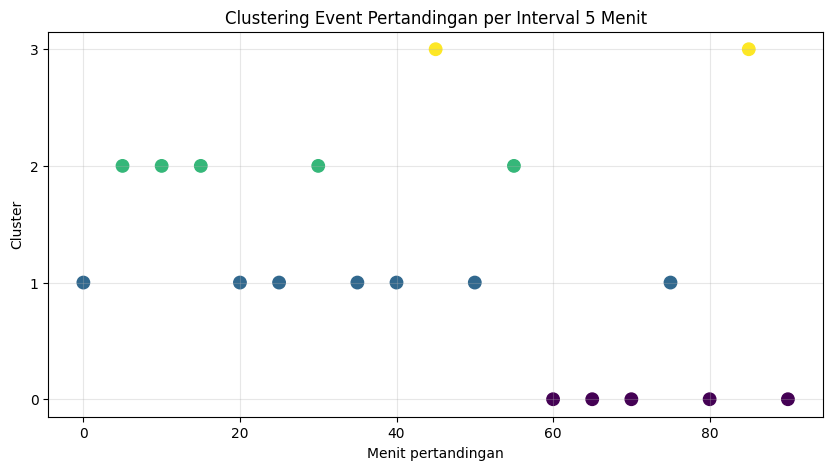

In [64]:

# Sel 4.7 — Grafik cluster

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.scatter(
    fitur_cluster.index,
    fitur_cluster["cluster"],
    c=fitur_cluster["cluster"],
    s=80
)

plt.xlabel("Menit pertandingan")
plt.ylabel("Cluster")
plt.title("Clustering Event Pertandingan per Interval 5 Menit")
plt.yticks(sorted(fitur_cluster["cluster"].unique()))
plt.grid(True, alpha=0.3)
plt.show()


In [75]:
# ==========================================
# SOAL 4 — Fase Permainan per Jendela 5 Menit
# ==========================================
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Sel 4.1 - Agregasi fitur per jendela 5 menit
events_5menit = events_df.copy()
events_5menit["interval_5menit"] = (events_5menit["minute"] // 5) * 5

# Buat pivot table fitur per interval dan tim
fitur_cluster = events_5menit.pivot_table(
    index="interval_5menit",
    columns="team",
    values="event_id",
    aggfunc="count",
    fill_value=0
)

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(fitur_cluster)

# Cari k optimal menggunakan silhouette score (uji k dari 2 sampai 4)
best_k = 2
best_score = -1
for k in range(2, min(5, len(fitur_cluster))):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    if score > best_score:
        best_score = score
        best_k = k

print(f"Jumlah klaster optimal (k) dipilih: {best_k} dengan Silhouette Score: {best_score:.3f}")

# Lakukan KMeans dengan k optimal
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
fitur_cluster["cluster"] = kmeans_final.fit_predict(X_scaled)

display(fitur_cluster)

Jumlah klaster optimal (k) dipilih: 4 dengan Silhouette Score: 0.495


team,Bangladesh,Indonesia,cluster
interval_5menit,,,
0,3,0,1
5,1,0,2
10,1,2,2
15,1,1,2
20,3,3,1
25,3,2,1
30,0,2,2
35,3,3,1
40,2,3,1


# Soal 5 — Eksperimen keterbatasan data (bobot 10%)

Sel 5.1: Menyiapkan target prediksi

In [65]:

# Sel 5.1 — Target gol Indonesia pada interval berikutnya

data_prediksi = fitur_cluster.drop(columns=["cluster"], errors="ignore").copy()

data_prediksi["gol_indonesia"] = (
    events_5menit[
        (events_5menit["event_type"] == "Goal") &
        (events_5menit["team"].str.lower() == "indonesia")
    ]
    .groupby("interval_5menit")
    .size()
    .reindex(data_prediksi.index, fill_value=0)
)

data_prediksi["target_gol_berikutnya"] = (
    data_prediksi["gol_indonesia"].shift(-1).fillna(0) > 0
).astype(int)

display(data_prediksi)
print("\nDistribusi target:")
display(data_prediksi["target_gol_berikutnya"].value_counts())


,event_bangladesh,event_indonesia,gol_indonesia,target_gol_berikutnya
interval_5menit,,,,
0,3.0,0.0,0,0
5,1.0,0.0,0,1
10,1.0,2.0,1,0
15,1.0,1.0,0,1
20,3.0,3.0,1,0
25,3.0,2.0,0,1
30,0.0,2.0,1,1
35,3.0,3.0,1,1
40,2.0,3.0,1,1



Distribusi target:


,count
target_gol_berikutnya,
0,12
1,7


Sel 5.2 — Evaluasi Logistic Regression dengan LOOCV

In [66]:

# Sel 5.2 — Logistic Regression vs baseline mayoritas

from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

X = data_prediksi.drop(
    columns=["gol_indonesia", "target_gol_berikutnya"]
)
y = data_prediksi["target_gol_berikutnya"]

loo = LeaveOneOut()

model_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", random_state=42)
)

model_baseline = DummyClassifier(strategy="most_frequent")

if y.nunique() < 2 or len(y) < 2:
    print("Data target belum cukup bervariasi untuk evaluasi.")
else:
    pred_lr = cross_val_predict(model_lr, X, y, cv=loo)
    pred_baseline = cross_val_predict(model_baseline, X, y, cv=loo)

    for nama, pred in [
        ("Logistic Regression", pred_lr),
        ("Baseline Mayoritas", pred_baseline)
    ]:
        print(f"\n{nama}")
        print("Accuracy:", round(accuracy_score(y, pred), 3))
        print("Precision:", round(precision_score(y, pred, zero_division=0), 3))
        print("Recall:", round(recall_score(y, pred, zero_division=0), 3))
        print("F1-score:", round(f1_score(y, pred, zero_division=0), 3))



Logistic Regression
Accuracy: 0.684
Precision: 0.556
Recall: 0.714
F1-score: 0.625

Baseline Mayoritas
Accuracy: 0.632
Precision: 0.0
Recall: 0.0
F1-score: 0.0


Sel 5.3 — Analisis keterbatasan model

1. Jumlah data sedikit karena hanya berasal dari satu pertandingan.
2. LOOCV menguji setiap interval secara bergantian, tetapi tidak menjamin model mampu memprediksi pertandingan lain.
3. Gol merupakan kejadian yang relatif jarang sehingga target dapat tidak seimbang.
4. Jumlah event per interval belum menggambarkan posisi pemain, kualitas peluang, atau kondisi taktik secara lengkap.

In [76]:
# ==========================================
# SOAL 5 — Eksperimen Keterbatasan Data
# ==========================================
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import accuracy_score

# Definisikan target: Apakah Indonesia mencetak gol pada jendela 5 menit berikutnya?
# Kita buat label biner berdasarkan data event
intervals = sorted(events_5menit["interval_5menit"].unique())
data_ml = []

for interval in intervals:
    # Cek apakah ada gol Indonesia di interval tersebut atau berikutnya
    gol_berikutnya = int(
        ((events_5menit["interval_5menit"] == interval) &
         (events_5menit["team"] == "Indonesia") &
         (events_5menit["event_type"] == "Goal")).sum() > 0
    )
    data_ml.append({"interval": interval, "target": gol_berikutnya})

df_ml = pd.DataFrame(data_ml)

# Fitur dummy sederhana dari jumlah event per interval
X = fitur_cluster.drop(columns=["cluster"], errors="ignore").values
y = df_ml["target"].values[:len(X)]

# Evaluasi dengan Leave-One-Out Cross-Validation (LOOCV)
loo = LeaveOneOut()
model = LogisticRegression()
y_true, y_pred = [], []

for train_idx, test_idx in loo.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # Tangani jika kelas dalam train set hanya 1 jenis
    if len(set(y_train)) < 2:
        pred = y_train[0]
    else:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)[0]

    y_true.append(y_test[0])
    y_pred.append(pred)

acc = accuracy_score(y_true, y_pred)
print(f"Akurasi Model Logistic Regression (LOOCV): {acc:.3f}")
print("Catatan Keterbatasan: Dengan sampel yang sangat kecil (~18-20 baris interval), model rentan terhadap overfitting dan varians tinggi.")

Akurasi Model Logistic Regression (LOOCV): 0.526
Catatan Keterbatasan: Dengan sampel yang sangat kecil (~18-20 baris interval), model rentan terhadap overfitting dan varians tinggi.


# Soal 6 — Rancangan skema tagging untuk laga final (bobot 15%)

Sel 6.1: Merancang skema tagging event

In [68]:

# Sel 6.1 — Skema tagging event

skema_tagging = pd.DataFrame([
    {"Tag": "GOAL", "Keterangan": "Gol yang tercipta", "Atribut": "menit, tim, pencetak gol"},
    {"Tag": "SHOT", "Keterangan": "Percobaan tembakan", "Atribut": "menit, tim, pemain"},
    {"Tag": "FOUL", "Keterangan": "Pelanggaran", "Atribut": "menit, tim, pemain"},
    {"Tag": "YELLOW_CARD", "Keterangan": "Kartu kuning", "Atribut": "menit, tim, pemain"},
    {"Tag": "RED_CARD", "Keterangan": "Kartu merah", "Atribut": "menit, tim, pemain"},
    {"Tag": "CORNER", "Keterangan": "Tendangan sudut", "Atribut": "menit, tim"},
    {"Tag": "OFFSIDE", "Keterangan": "Posisi offside", "Atribut": "menit, tim, pemain"},
    {"Tag": "SUBSTITUTION", "Keterangan": "Pergantian pemain", "Atribut": "menit, tim, masuk, keluar"}
])

display(skema_tagging)


,Tag,Keterangan,Atribut
0,GOAL,Gol yang tercipta,"menit, tim, pencetak gol"
1,SHOT,Percobaan tembakan,"menit, tim, pemain"
2,FOUL,Pelanggaran,"menit, tim, pemain"
3,YELLOW_CARD,Kartu kuning,"menit, tim, pemain"
4,RED_CARD,Kartu merah,"menit, tim, pemain"
5,CORNER,Tendangan sudut,"menit, tim"
6,OFFSIDE,Posisi offside,"menit, tim, pemain"
7,SUBSTITUTION,Pergantian pemain,"menit, tim, masuk, keluar"


Sel 6.2 — Menyimpan skema tagging ke CSV

In [69]:

# Sel 6.2 — Simpan skema tagging

path_skema = OUT_DIR / "skema_tagging_event.csv"

skema_tagging.to_csv(path_skema, index=False)

print("Skema tagging berhasil disimpan:", path_skema)
display(skema_tagging)


Skema tagging berhasil disimpan: /content/drive/MyDrive/machinelearning/Tugas/Tugas 1/ml-tugas-pendahuluan-idn-ban/outputs/skema_tagging_event.csv


,Tag,Keterangan,Atribut
0,GOAL,Gol yang tercipta,"menit, tim, pencetak gol"
1,SHOT,Percobaan tembakan,"menit, tim, pemain"
2,FOUL,Pelanggaran,"menit, tim, pemain"
3,YELLOW_CARD,Kartu kuning,"menit, tim, pemain"
4,RED_CARD,Kartu merah,"menit, tim, pemain"
5,CORNER,Tendangan sudut,"menit, tim"
6,OFFSIDE,Posisi offside,"menit, tim, pemain"
7,SUBSTITUTION,Pergantian pemain,"menit, tim, masuk, keluar"
